In [78]:
import pandas as pd
import numpy as np
import random
import warnings
import matplotlib.pyplot as plt
import seaborn as sns
from  lightgbm import LGBMRegressor,LGBMClassifier,log_evaluation,early_stopping

import warnings #avoid some negligible errors

from sklearn.metrics import ConfusionMatrixDisplay, classification_report, make_scorer, precision_recall_curve, auc
from datetime import datetime, timedelta
import random
from sklearn.metrics import average_precision_score,  accuracy_score, precision_score, recall_score, f1_score, \
    precision_recall_curve, auc, roc_curve, roc_auc_score, confusion_matrix
from xgboost import XGBClassifier
import gc
import matplotlib as mpl
import ydata_profiling
from ydata_profiling import ProfileReport
from sklearn.model_selection import KFold, RandomizedSearchCV, StratifiedKFold, train_test_split
# from pandas_profiling import ProfileReport
import plotly.figure_factory as ff
# from phik import resources
from phik.binning import bin_data
from phik.report import plot_correlation_matrix
from plotnine import *
from plotnine.data import *
import patchworklib as pw

from skopt import BayesSearchCV
from skopt.space import Real, Integer, Categorical

#The filterwarnings () method is used to set warning filters, which can control the output method and level of warning information.
warnings.filterwarnings('ignore')

# Configuration
warnings.filterwarnings('ignore')

SEED = 77

# --- 1. Set Seed ---
def seed_everything(seed):
    np.random.seed(seed)
    random.seed(seed)
    
seed_everything(seed=SEED)

pd.set_option('display.max_columns', 50)
pd.set_option('display.max_rows', 150)
pd.options.display.float_format = "{:,.2f}".format

def to_decimal(valor, casas_dec = 0, as_percent = False, matplotTextAxe=None):
    """
    valor: Vaor recebido que pode ser uma string um inteiro ou um Objeto matplotlib
    casas_dec: Números de Casas Decimais
    as_percent: True ou Flase, default False para mostrar como percentual.
    matplotTextAxe: Aceita os valores de 'x' ou 'y' indicando qual eixo ticklabels
    return: Retorna o valor formatado conforme os argumentos passados.
    """
    eixo = 0
    if matplotTextAxe != None:
        if matplotTextAxe not in ('x','y'): raise ValueError("Erro! matplotTextAxe")
        elif matplotTextAxe == 'x': eixo = 0
        else: eixo = 1
    v = ''
    if as_percent: v = '%'
    if isinstance(valor, mpl.text.Text): valor = valor.get_position()[eixo]
    if casas_dec == 0: return ("{:,.0f}".format(float(valor))) + v
    else: return ("{:,.2f}".format(float(valor))) + v
    
def limpa_memoria(variaveis: list=[]):
    #torch.cuda.empty_cache()
    plt.clf()# Limpa a figura atual
    plt.cla()# Limpa o gráfico atual
    plt.close('all')
    for i in variaveis:
        del i
    x = 1
    while x > 0:
        x = gc.collect()
    pass

def plota_confusion_matrix(y_true, y_pred):
    from sklearn.metrics import ConfusionMatrixDisplay
    fig, (ax1, ax2) = plt.subplots(nrows=1, ncols=2, figsize=(12, 5))

    disp = ConfusionMatrixDisplay.from_predictions(
        y_true,
        y_pred,
        # normalize='true', None
        cmap='Blues', 
        ax=ax1
    )
    ax1.set_title("Matriz Absoluta")

    disp2 = ConfusionMatrixDisplay.from_predictions(
        y_true,
        y_pred,
        normalize='true',
        values_format='.0%',
        cmap='Blues',
        ax=ax2
    )

    ax2.set_title('Matriz Normalizada (%)')
    
    plt.show()
    limpa_memoria();

def tune_model(modelo, param_grid, X, y, n_iter=50, scoring='average_precision', random_state=SEED, n_jobs=6):
    from sklearn.model_selection import StratifiedKFold
    
    nm_modelo = modelo.__class__.__name__
    print(f"Tuning do modelo: {nm_modelo}")

    #Validação Cruzada
    skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=random_state)   #KFold(n_splits=n_iter, shuffle=True, random_state=random_state)

    #RandomizedSearchCV para busca mais rápida
    grid_search = RandomizedSearchCV( 
    estimator=modelo, 
    param_distributions=param_grid,
    n_iter=n_iter,
    cv=skf,
    scoring=scoring,
    n_jobs=n_jobs,
    random_state=random_state, 
    verbose=1
    )

    grid_search.fit(X,y)
    print(f"Melhores Hiperparâmetros para {nm_modelo}:{grid_search.best_params_}")
    limpa_memoria()
    #Retorna o modelo treinado com os melhores hiperparâmetros
    return grid_search.best_estimator_

def plot_missing_bar(df: pd.DataFrame, top=30, figsize=(9, 7)):
    miss = (df.isna().mean()*100).sort_values(ascending=False).head(top)
    plt.figure(figsize=figsize)
    plt.barh(miss.index[::-1], miss.values[::-1])
    plt.xlabel("% de ausentes")
    plt.title(f"Top {top} variáveis com maior proporção de valores ausentes")
    plt.tight_layout()
    plt.show()

def plota_classificarion_report(ytest, ypred):

    # y_test, y_pred
    rep = classification_report(ytest, ypred, output_dict=True, zero_division=0)
    df_rep = pd.DataFrame(rep).T

    # ordenar e formatar
    cols_order = ["precision", "recall", "f1-score", "support"]
    df_rep = df_rep[cols_order]
    df_rep[["precision", "recall", "f1-score"]] = df_rep[["precision", "recall", "f1-score"]].round(2)


    # usa df_rep do bloco anterior
    plt.figure(figsize=(6, 3.2))
    sns.heatmap(
        df_rep[["precision","recall","f1-score"]],
        annot=True, fmt=".3f",
        linewidths=0.5, linecolor="white",
        cbar=True
    )
    plt.title("Classification Report (Precision / Recall / F1)")
    plt.ylabel("Classe")
    plt.xlabel("Métrica")
    plt.tight_layout()
    plt.show()
    plt.close();

def garantee_dtime(column:pd.Series) -> pd.Series:
    column = pd.to_datetime(column, errors='coerce')
    return column

def plota_proporcao(df: pd.DataFrame, column: str, titulo: str = "Quantitativo dos valores"):

    values = ( df[column].value_counts(dropna=False) / df[column].shape[0] ) * 100
    values = pd.DataFrame(values).reset_index()

    plt.figure(figsize=(6, 5))
    ax = sns.barplot(x=values[column], y=values['count'], palette='coolwarm', hue=values[column].map({0: 'Negativo', 1: 'Positivo'}))
    plt.title(label=titulo)
    plt.xlabel(f'Valores para {column}')
    plt.ylabel('Proporção dos registros')

    plt.ylim(0, 110) 

    #Rótulo das barras
    for p in ax.patches:
        h = p.get_height()
        ax.annotate(f"{h:.2f}%", 
                    (p.get_x() + p.get_width()/2, h),
                    ha='center',
                    va='bottom',
                    xytext=(0,5), 
                    textcoords="offset points"
                    )
    plt.show()
    limpa_memoria();

def val_cross(models, param_spaces, n_iter, X, y, x_teste=None, y_teste=None, njobs=6):

    from datetime import datetime as dtm
    from sklearn.model_selection import StratifiedKFold, RandomizedSearchCV
    import numpy as np
    import pandas as pd
    import matplotlib.pyplot as plt

    print('Início do modelo...')
    print(f'Hora Início...: {dtm.now().hour}:{dtm.now().minute}h')

    cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)

    print(f'Feitas validações cruzadas. N-Iter = {n_iter}')
    print(f'Métrica de avaliação - PR-AUC')

    scorer = 'average_precision'
    # scorer = 'balanced_accuracy' #TODO:

    results = {}
    best_models = {}
    best_params = {}
    mean_scores = {}
    best_thresholds = {}

    # 🔵 Controle do melhor modelo global
    best_global_score = -np.inf
    best_global_name = None
    best_global_model = None

    for nome, model in models.items():

        print(f'\n🔍 Otimizando modelo: {nome}...')
        print(f'Hora Início..{nome}.: {dtm.now().hour}:{dtm.now().minute}h')

        search = RandomizedSearchCV(
            estimator=model,
            param_distributions=param_spaces[nome],
            n_iter=n_iter,
            cv=cv,
            scoring=scorer,
            n_jobs=njobs,
            random_state=SEED,
            # verbose=0,
            return_train_score=False
        )

        search.fit(X, y)
        print(f'Hora FIM..{nome}.: {dtm.now().hour}:{dtm.now().minute}h')
        
        best_models[nome] = search.best_estimator_
        # 🔵 Calcular threshold ótimo no conjunto de teste (F1 máximo)
        if x_teste is not None and y_teste is not None:

            from sklearn.metrics import precision_recall_curve

            y_prob_test = search.best_estimator_.predict_proba(x_teste)[:, 1]
            precision_t, recall_t, thresholds_t = precision_recall_curve(y_teste, y_prob_test)

            f1_scores = 2 * (precision_t[:-1] * recall_t[:-1]) / (precision_t[:-1] + recall_t[:-1] + 1e-10)

            best_idx = np.argmax(f1_scores)
            best_threshold = thresholds_t[best_idx]

            # salvar threshold
            if 'best_thresholds' not in locals():
                best_thresholds = {}

            best_thresholds[nome] = best_threshold
        best_params[nome] = search.best_params_

        best_index = search.best_index_

        fold_scores = [
            search.cv_results_[f'split{i}_test_score'][best_index]
            for i in range(cv.get_n_splits())
        ]

        results[nome] = fold_scores
        mean_scores[nome] = np.mean(fold_scores)

        print(f"✅ Melhor PR-AUC (CV): {search.best_score_:.4f}")
        print(f"📌 Melhores parâmetros: {search.best_params_}")

        # 🔥 Verifica se é o melhor global
        if search.best_score_ > best_global_score:
            best_global_score = search.best_score_
            best_global_name = nome
            best_global_model = search.best_estimator_
            best_global_estimator = search.best_estimator_

    results_df = pd.DataFrame(results)
    

    print("\n🏆 MELHOR MODELO GLOBAL:")
    print(f"Modelo: {best_global_name}")
    print(f"PR-AUC médio (CV): {best_global_score:.4f}")

    # 🔥 Se existir conjunto de teste → avaliar
    if x_teste is not None and y_teste is not None:

        y_prob = best_global_model.predict_proba(x_teste)[:, 1]
        from sklearn.metrics import average_precision_score

        test_ap = average_precision_score(y_teste, y_prob)

        print(f"PR-AUC no conjunto de teste: {test_ap:.4f}")

    return (
        results_df,
        best_models,
        best_params,
        best_thresholds,   # ← novo
        best_global_name,
        best_global_model,
        best_global_score,
        best_global_estimator
    )

def plota_resultados_boxplot(results_df, y_train, figsize=(8,5), dpis=150):
    # =============================
    # 📊 BOXPLOT
    # =============================

    plt.figure(figsize=figsize, dpi=dpis)
    ax = results_df.boxplot()

    baseline = y_train.mean()

    plt.axhline(
        baseline,
        linestyle='--',
        linewidth=1.5,
        label=f'Baseline (Prevalência) = {baseline:.3f}',
        color='red'
    )

    medians = results_df.median()

    for i, median in enumerate(medians):
        plt.text(
            i + 1,
            median + 0.01,
            f'{median:.3f}',
            horizontalalignment='center',
            fontsize=10,
            fontweight='bold'
        )


    # =============================
    # 🔎 OUTLIERS + MÁXIMO (Q4)
    # =============================

    for i, col in enumerate(results_df.columns):
        values = results_df[col].dropna().values
        
        q1 = np.percentile(values, 25)
        q3 = np.percentile(values, 75)
        iqr = q3 - q1
        upper_bound = q3 + 1.5 * iqr

        max_value = values.max()
        outliers = values[values > upper_bound]

        # 🔺 Se houver outlier → marcar o maior outlier
        if len(outliers) > 0:
            max_outlier = outliers.max()
            
            plt.annotate(
                f'Out: {max_outlier:.3f}',
                xy=(i + 1, max_outlier),
                # xytext=(i + 1.15, max_outlier + 0.05),
                xytext=(i + 1, max_outlier + 0.015),
                arrowprops=dict(arrowstyle='->', linewidth=1),
                fontsize=9,
                ha='right'
            )

            # 📈 Também marcar o máximo não-outlier (whisker superior)
            whisker_max = values[values <= upper_bound].max()

            plt.annotate(
                f'Max: {whisker_max:.3f}',
                xy=(i + 1, whisker_max),
                # xytext=(i - 0.25, whisker_max + 0.03),
                xytext=(i + 1, whisker_max + 0.015),
                arrowprops=dict(arrowstyle='->', linewidth=1),
                fontsize=9,
                ha='right'
            )

        # 📈 Se não houver outlier → marcar apenas o máximo
        else:
            plt.annotate(
                f'Max: {max_value:.3f}',
                xy=(i + 1, max_value),
                xytext=(i + 1.15, max_value + 0.05),
                arrowprops=dict(arrowstyle='->', linewidth=1),
                fontsize=9,
                ha='left'
            )

    plt.title("Validação Cruzada (5-fold) - PR-AUC para Predição de Sepse")
    plt.ylabel("PR-AUC")
    plt.xticks(rotation=15)
    plt.grid(True, linestyle='--', alpha=0.7)
    plt.ylim((0.0, 1.0))
    plt.legend()
    plt.tight_layout()
    plt.show()
    plt.close()

    limpa_memoria()

from sklearn.metrics import balanced_accuracy_score, matthews_corrcoef


def plota_calculate_metrics(y_true, y_pred, y_pred_proba):
    """Calculate comprehensive set of metrics for imbalanced classification."""
    tn, fp, fn, tp = confusion_matrix(y_true, y_pred).ravel()
    
    specificity = tn / (tn + fp)
    sensitivity = tp / (tp + fn)
    precision = precision_score(y_true, y_pred)
    recall = recall_score(y_true, y_pred)
    f1 = f1_score(y_true, y_pred)
    bal_accuracy = balanced_accuracy_score(y_true, y_pred)
    mcc = matthews_corrcoef(y_true, y_pred)
    
    roc_auc = roc_auc_score(y_true, y_pred_proba)
    avg_precision = average_precision_score(y_true, y_pred_proba)
    precision_curve, recall_curve, _ = precision_recall_curve(y_true, y_pred_proba)
    pr_auc = auc(recall_curve, precision_curve)
    
    return {
        'ROC_AUC': roc_auc,
        'PR_AUC': pr_auc,
        'Average_Precision': avg_precision,
        'F1_Score': f1,
        'Balanced_Accuracy': bal_accuracy,
        'MCC': mcc,
        'Specificity': specificity,
        'Sensitivity': sensitivity,
        'Precision': precision,
        'Recall': recall
    }



In [79]:
# Carrega os dados
df_label = pd.read_csv('Data/training_data/SepsisLabel_train.csv').drop_duplicates()
df_labs = pd.read_csv('Data/training_data/measurement_lab_train.csv').drop_duplicates()
df_measure_meds = pd.read_csv('Data/training_data/measurement_meds_train.csv').drop_duplicates()
df_measure_obs = pd.read_csv('Data/training_data/measurement_observation_train.csv').drop_duplicates()
df_demographics = pd.read_csv('Data/training_data/person_demographics_episode_train.csv').drop_duplicates()

# Padroniza os datatypes das datas para Datetime
df_label['measurement_datetime'] = garantee_dtime(df_label['measurement_datetime'])
df_labs['measurement_datetime'] = garantee_dtime(df_labs['measurement_datetime'])
df_measure_meds['measurement_datetime'] = garantee_dtime(df_measure_meds['measurement_datetime'])
df_measure_obs['measurement_datetime'] = garantee_dtime(df_measure_obs['measurement_datetime'])
df_demographics['visit_start_date'] = garantee_dtime(df_demographics['visit_start_date'])

# Altera todas as colunas de datas para o mesmo nome "datetime"
df_label.rename(columns={'measurement_datetime': 'datetime'}, inplace=True)
df_labs.rename(columns={'measurement_datetime': 'datetime'}, inplace=True)
df_measure_meds.rename(columns={'measurement_datetime': 'datetime'}, inplace=True)
df_measure_obs.rename(columns={'measurement_datetime': 'datetime'}, inplace=True)
df_demographics.rename(columns={'visit_start_date': 'datetime'}, inplace=True)

In [80]:
# from tqdm.auto import tqdm
# tqdm.pandas()
# df_labelbkp = df_label.copy() #.progress_apply(lambda x: x[:10] if pd.notna(x) else None)

In [81]:
df = df_label.sort_values(['person_id', 'datetime']).copy()

# Dia relativo ao início da internação
df['qtty_days'] = (
    df.groupby('person_id')['datetime']
    .transform(lambda x: (x - x.min()).dt.days)
)

first_sepsis = (
    df[df['SepsisLabel'] == 1]
    .groupby('person_id')
    .first()
    .reset_index()
)

first_record = (
    df.groupby('person_id')
    .first()
    .reset_index()
)

base = first_sepsis[['person_id', 'datetime']].merge(
    first_record,
    on='person_id',
    suffixes=('_sepse', '_base')
)

rows = []

for _, row in base.iterrows():

    sepse_time = row['datetime_sepse']

    # Criar D-1 e D-2
    for lag in [1, 2]:

        new_row = row.copy()

        new_row['datetime'] = sepse_time - pd.Timedelta(days=lag)
        new_row['qtty_days'] = new_row['qtty_days'] - lag  # ajusta dia relativo

        rows.append(new_row)

df_new = pd.DataFrame(rows)

# Ajustar colunas para ficarem iguais ao original
df_new = df_new[df.columns]

df = pd.concat([df, df_new], ignore_index=True)

df = df.sort_values(['person_id', 'datetime']).copy()

# Última data por paciente
last_date = (
    df.groupby('person_id')['datetime']
    .max()
    .reset_index()
    .rename(columns={'datetime': 'last_datetime'})
)

df = df.merge(last_date, on='person_id', how='left')

# Calcular total de dias observados
df['total_days_observed'] = (
    (df['last_datetime'] - 
     df.groupby('person_id')['datetime'].transform('min')
    ).dt.days
)

first_sepsis = (
    df[df['SepsisLabel'] == 1]
    .groupby('person_id')['datetime']
    .min()
    .reset_index()
    .rename(columns={'datetime': 'first_sepsis_datetime'})
)

df = df.merge(first_sepsis, on='person_id', how='left')

df = df[
    (df['first_sepsis_datetime'].isna()) | 
    (df['datetime'] <= df['first_sepsis_datetime'])
].copy()


df['datetime'] = pd.to_datetime(df['datetime'], errors='coerce')

In [ ]:

df[df['person_id']==16748754].head()

In [83]:
# TRATA AS COLUNAS
df_measure_meds.rename(columns={	
                                'Systolic blood pressure': 'systolic_pressure',
                                'Diastolic blood pressure': 'diastolic_pressure',
                                'Body temperature': 'temperature',
                                'Respiratory rate': 'resp_rate',
                                'Heart rate': 'heart_rate',
                                'Measurement of oxygen saturation at periphery': 'oxygen_periphery', 
                                'Oxygen/Gas total [Pure volume fraction] Inhaled gas': 'oxygen_total'}, inplace=True)

df_measure_obs = df_measure_obs[['person_id', 
                                'visit_occurrence_id', 
                                'datetime',
                                'Left pupil Diameter Auto', 
                                'Right pupil Diameter Auto', 
                                'Glasgow coma scale',
                                'Capillary refill [Time]', 
                                'Pulse',
                                'Arterial pulse pressure']]

df_measure_obs.rename(columns={
                         
                            'Left pupil Diameter Auto': 'l_pupil_diameter', 
                            'Right pupil Diameter Auto': 'r_pupil_diameter', 
                            'Glasgow coma scale': 'glasgow',
                            'Capillary refill [Time]': 'capillary_refil', 
                            'Pulse': 'pulse',
                            'Arterial pulse pressure': 'art_pressure'
                            }, inplace=True)



#LABS Data
rename_cols = {
    'Bilirubin.total [Moles/volume] in Serum or Plasma': 'bilirubin',
    'C reactive protein [Mass/volume] in Serum or Plasma': 'c_reactive_protein',
    'Procalcitonin [Mass/volume] in Serum or Plasma': 'procalcitonin',
    'Lactate [Moles/volume] in Blood': 'lactate',
    'Creatinine [Mass/volume] in Blood': 'creatinine',
    'Partial thromboplastin time': 'thromboplastin_time', 
    'White blood cell count': 'white_cell', 
    'Hemoglobin [Moles/volume] in Blood': 'hemoglobin', 
    'Base excess in Venous blood by calculation': 'base_excess_venous',
    'Base excess in Arterial blood by calculation': 'base_excess_arterial',
    'Phosphate [Moles/volume] in Serum or Plasma': 'phosphate',
    'Potassium [Moles/volume] in Blood': 'potassium',
    'Neutrophil Ab [Units/volume] in Serum': 'neutrophil_ap',
    'Bicarbonate [Moles/volume] in Arterial blood': 'bicarbonate_arterial',
    'Hematocrit [Volume Fraction] of Blood': 'hematocrit',
    'Glucose [Moles/volume] in Serum or Plasma': 'glucose',
    'Calcium [Moles/volume] in Serum or Plasma': 'calcium',
    'Chloride [Moles/volume] in Blood': 'chloride',
    'Sodium [Moles/volume] in Serum or Plasma': 'sodium',
    'Carbon dioxide [Partial pressure] in Venous blood': 'carbon_dioxide_venous',
    'Oxygen [Partial pressure] in Venous blood': 'oxygen_venous',
    'Albumin [Mass/volume] in Serum or Plasma': 'albumin_venous',
    'Bicarbonate [Moles/volume] in Venous blood': 'bicarbonate_venous',
    'Oxygen [Partial pressure] in Arterial blood': 'oxygen_arterial',
    'Carbon dioxide [Partial pressure] in Arterial blood': 'carbon_dioxide_arterial',
    'Interleukin 6 [Mass/volume] in Body fluid': 'interleukin6',
    'Magnesium [Moles/volume] in Blood': 'magnesium', 
    'Prothrombin time (PT)': 'prothrombin_time',
    'Fibrinogen measurement': 'fibrinogen', 
    'Bilirubin measurement': 'bilirubin_measurement',
    ' activated': 'activated', 
    'Total white blood count': 'white_blood',
    'Platelet count': 'platelet', 
    'Blood venous pH': 'venous_ph',
    'D-dimer level': 'd_dimer_level', 
    'Blood arterial pH': 'arterial_ph',
    'Ionised calcium measurement': 'ionised_calcium'
}

df_labs.rename(columns=rename_cols, inplace=True)
# df_labs = df_labs[cols_to_use]

In [84]:
cap_map = {
    'Normal capillary filling': 'normal',
    'Increased capillary filling time': 'increased', 
    'Decreased capillary filling time': 'decreased', 
    np.nan: 'none'
}

df_measure_obs['capillary_refil'] = df_measure_obs['capillary_refil'].map(cap_map)
df_measure_obs = df_measure_obs.rename(columns={'capillary_refil': 'capillary'})

df_measure_obs = (
        pd.concat([df_measure_obs, pd.get_dummies(df_measure_obs, columns=['capillary', 'art_pressure', 'pulse'])
                   .drop(columns=['l_pupil_diameter', 'r_pupil_diameter', 'glasgow', 'person_id', 'visit_occurrence_id', 'datetime'])], axis=1)
        .drop(columns=['capillary', 'pulse', 'art_pressure'])
        )  

df_measure_obs[['capillary_decreased',	'capillary_increased',	'capillary_none',
                'capillary_normal',	'art_pressure_Absent',	'art_pressure_Present',
                'art_pressure_Weak', 'pulse_Absent', 'pulse_Present', 'pulse_Weak']] = df_measure_obs[['capillary_decreased',	'capillary_increased',	'capillary_none',
                'capillary_normal',	'art_pressure_Absent',	'art_pressure_Present',
                'art_pressure_Weak', 'pulse_Absent', 'pulse_Present', 'pulse_Weak']].astype('int32').fillna(0)


In [85]:
df_label = df.copy()
#df_label          = df_label.sort_values(by=['person_id', 'datetime'])
df_labs           = df_labs.sort_values(by=['person_id', 'datetime']).drop(columns='visit_occurrence_id')
df_measure_meds   = df_measure_meds.sort_values(by=['person_id', 'datetime']).drop(columns='visit_occurrence_id')
df_measure_obs    = df_measure_obs.sort_values(by=['person_id', 'datetime']).drop(columns='visit_occurrence_id')
df_demographics   = df_demographics.sort_values(by=['person_id', 'datetime']).drop(columns='visit_occurrence_id')

df_label['datetime'] = pd.to_datetime(df_label['datetime'], errors='coerce')
df_label['last_datetime'] = pd.to_datetime(df_label['last_datetime'], errors='coerce')
df_label['first_sepsis_datetime'] = pd.to_datetime(df_label['first_sepsis_datetime'], errors='coerce')

df_demographics = pd.get_dummies(df_demographics, columns=['gender'], dtype=int).rename(columns={'gender_FEMALE': 'female', 'gender_MALE': 'male'})

df_final = (
    # df_label.merge(df_demographics, on=['person_id'], how='left')
    df_label.merge(df_labs, on=['person_id', 'datetime'], how='left')
    .merge(df_measure_meds, on=['person_id', 'datetime'], how='left')
    .merge(df_measure_obs, on=['person_id', 'datetime'], how='left')     
         )

In [86]:
last_not_null = lambda x: x.dropna().iloc[-1] if x.notna().any() else np.nan

LIMITS = {
    'temperature': (32.0, 43.0),           # Hipotermia grave → Hiperpirexia letal
    'hematocrit': (12.0, 70.0),            # Anemia extrema → Policitemia neonatal
    'base_excess_venous': (-30.0, 25.0),   # Acidose láctica → Alcalose iatrogênica HCO3
    'base_excess_arterial': (-30.0, 25.0), # ↑
    'phosphate': (0.1, 15.0),              # Hipofosfatemia grave → Rabdomiólise
    'potassium': (1.5, 9.5),               # Hipocalemia letal → Hipercalemia aguda
    'bilirubin': (0.0, 50.0),              # Neonatal grave → Insuficiência hepática
    'neutrophil_ap': (0.0, 80.0),          # Neutropenia → Neutrofilia extrema sepse
    'bicarbonate_arterial': (2.0, 45.0),   # Acidose → Alcalose metabólica grave
    'glucose': (5.0, 800.0),               # Hipoglicemia grave → Hiperglicemia HHS
    'calcium': (4.0, 18.0),                # Hipocalcemia → Hipercalcemia paratireoide
    'chloride': (70.0, 130.0),             # Acidose hiperclorêmica → Alcalose hipoclorêmica
    'sodium': (105.0, 185.0),              # Hiponatremia grave → Hipernatremia letal
    'c_reactive_protein': (0.0, 600.0),    # Normal → Sepse neonatal grave
    'carbon_dioxide_venous': (10.0, 70.0), # Acidose respiratória → Alcalose hipercapnia
    'oxygen_venous': (10.0, 85.0),         # SvO2 choque → Hiperoxia venosa
    'albumin_venous': (0.5, 7.0),          # Hipoalbuminemia grave → Desidratação extrema
    'bicarbonate_venous': (2.0, 45.0),     # ↑
    'oxygen_arterial': (20.0, 650.0),      # Hipoxemia grave → Hiperoxia suplementada
    'carbon_dioxide_arterial': (10.0, 120.0), # Acidose respiratória grave → Hipercapnia
    'interleukin6': (0.0, 50000.0),        # Normal → Sepse grave (pg/mL)
    'magnesium': (0.2, 8.0),               # Hipomagnesemia grave → Hipermagnesemia iatrogênica
    'prothrombin_time': (5.0, 120.0),      # Coagulação hiperativa → CIVD grave
    'procalcitonin': (0.0, 500.0),         # Normal → Sepse fulminante
    'lactate': (0.2, 25.0),                # Normal → Choque lático refratário
    'creatinine': (0.0, 10.0),             # Normal → IRA estágio 3 grave
    'fibrinogen': (20.0, 1200.0),          # Hipofibrinogenemia → Resposta inflamatória aguda
    'bilirubin_measurement': (0.0, 50.0),  # ↑
    'thromboplastin_time': (5.0, 120.0),   # ↑ PT/INR
    'activated': (20.0, 200.0),            # aPTT normal → CIVD grave
    'white_blood': (0.0, 120.0),           # Leucopenia → Leucocitose extrema (10³/µL)
    'platelet': (1.0, 2000.0),             # Trombocitopenia grave → Trombocitose reativa
    'white_cell': (0.0, 120.0),            # ↑
    'venous_ph': (6.5, 7.65),              # Acidose letal → Alcalose extrema
    'd_dimer_level': (0.0, 50.0),          # Normal → CIVD/Tromboembolismo massivo (µg/mL)
    'arterial_ph': (6.5, 7.65),            # ↑
    'hemoglobin': (3.0, 28.0),             # Anemia grave → Policitemia neonatal
    'ionised_calcium': (0.3, 3.5),         # Hipocalcemia grave → Hipercalcemia letal (mmol/L)
    'systolic_pressure': (20.0, 220.0),    # Choque → Crise hipertensiva
    'diastolic_pressure': (10.0, 140.0),   # ↑
    'resp_rate': (0.0, 120.0),             # Apneia → Taquipneia extrema neonatal
    'heart_rate': (20.0, 300.0),           # Bradicardia grave → Taquicardia supraventricular
    'oxygen_periphery': (50.0, 102.0),     # Hipoxemia grave → Hiperoxia suplementada
    'oxygen_total': (50.0, 102.0),         # ↑
    'l_pupil_diameter': (0.5, 10.0),       # Miosis extrema → Midríase total
    'r_pupil_diameter': (0.5, 10.0),       # ↑
    'glasgow': (3.0, 15.0)                 # Coma → Normal
}


def apply_clinical_limits_nan(df, limits):
    df = df.copy()
    for col, (vmin, vmax) in limits.items():
        if col in df.columns:
            df.loc[
                (df[col] < vmin) | (df[col] > vmax),
                col
            ] = np.nan
    return df

df_final = apply_clinical_limits_nan(df_final, limits=LIMITS)


# DROPAR !!!!
### Colunas que estão totalmente nulas!

In [87]:
miss_to_drop = []

notok = ['person_id', 'datetime', 'SepsisLabel', 'qtty_days', 'last_datetime', 'first_sepsis_datetime', 'target_24h', 'target_48h', 'day', 'week']
encodeds = ['capillary_decreased', 'capillary_increased', 'capillary_none',
       'capillary_normal', 'art_pressure_Absent', 'art_pressure_Present',
       'art_pressure_Weak', 'pulse_Absent', 'pulse_Present', 'pulse_Weak']
ok = [c for c in df_final.columns if c not in notok + encodeds]


c1 = df_final[ok].describe()
# c2 = df[cols].describe()
for i in c1.columns:
    if np.isnan(c1[i]['max']):
        miss_to_drop.append(i)

df_final = df_final.drop(columns=miss_to_drop)
miss_to_drop

['calcium', 'creatinine', 'fibrinogen', 'ionised_calcium', 'oxygen_total']

# MARCA AS TARGETS 24h e 48h

In [88]:
df_final['sepse_24h'] = (df_final['qtty_days'] == -1).astype(int)
df_final['sepse_48h'] = (df_final['qtty_days'] == -2).astype(int)
cols_to_drop = ['SepsisLabel', 'datetime', 'qtty_days', 'last_datetime', 'first_sepsis_datetime']

df_final['day'] = pd.to_datetime(df_final['datetime'].dt.date, errors='coerce')
df_final['week'] = df_final['datetime'].dt.to_period('W-SUN')

# Dropa linhas com datas nulas
df_final = df_final[~df_final['datetime'].isna()].copy() 
df_final['datetime'].isna().sum()

# df_final[df_final['person_id']==16748754].head()

np.int64(0)

# Group by até a data limite

In [89]:
df['datetime'] = pd.to_datetime(df['datetime'])
df['first_sepsis_datetime'] = pd.to_datetime(df['first_sepsis_datetime'])
df['last_datetime'] = pd.to_datetime(df['last_datetime'])


df_final['cutoff24h'] = (
    np.where(
        df_final['first_sepsis_datetime'].notna(),
        df_final['first_sepsis_datetime'] - pd.Timedelta(hours=24),
        df_final['last_datetime']
             )
)

df_final['cutoff48h'] = (
    np.where(
        df_final['first_sepsis_datetime'].notna(),
        df_final['first_sepsis_datetime'] - pd.Timedelta(hours=48),
        df_final['last_datetime']
             )
)


df_final24h = df_final[df_final['datetime']<=df_final['cutoff24h']].copy()
df_final48h = df_final[df_final['datetime']<=df_final['cutoff48h']]

assert (df_final24h['datetime'] <= df_final24h['cutoff24h']).all()
assert (df_final48h['datetime'] <= df_final48h['cutoff48h']).all()


# PACIENTES SEM JANELA ANTES DA SEPSE / ENTRADA JÁ COM SEPSE NA INTERNAÇÂO

In [90]:
p_all = set(df_final['person_id'].unique())
p_24  = set(df_final24h['person_id'].unique())
p_48 = set(df_final48h['person_id'].unique())

lst24 = [int(c) for c in (p_all - p_24)]
lst48 = [int(c) for c in (p_all - p_48)]#

print(f"Shape24 antes: {df_final24h.shape}, Shape48 antes: {df_final48h.shape}")
df_final24h = df_final24h[~df_final24h['person_id'].isin(lst24)].copy().drop_duplicates(keep='last')
df_final48h = df_final48h[~df_final48h['person_id'].isin(lst48)].copy().drop_duplicates(keep='last')
print(f"\nShape24 depois: {df_final24h.shape}, Shape48 depois: {df_final48h.shape}")

# df_final[df_final['person_id'].isin(lst)].sort_values(by=['person_id', 'datetime'])

Shape24 antes: (279919, 65), Shape48 antes: (279127, 65)

Shape24 depois: (279916, 65), Shape48 depois: (279124, 65)


In [91]:
df_final24h = df_final24h.groupby(
    by=['person_id', 'cutoff24h'], as_index=False
).agg(
    sepse_24h=('sepse_24h', 'max'),
	# sepse_48h=(),
    qtty_days=('qtty_days', 'last'),
    total_days_observed=('total_days_observed','max'),
	# age_in_months=('age_in_months', 'max'), female=('female', 'max'), male=('male', 'max'), Só depois de agrupar 
    base_excess_venous=('base_excess_venous', last_not_null),	base_excess_arterial=('base_excess_arterial', last_not_null),
    phosphate=('phosphate', last_not_null), potassium=('potassium', last_not_null), bilirubin=('bilirubin', last_not_null), 
    neutrophil_ap=('neutrophil_ap', last_not_null), bicarbonate_arterial=('bicarbonate_arterial', last_not_null), hematocrit=('hematocrit', last_not_null),
    glucose=('glucose', last_not_null), chloride=('chloride', last_not_null), sodium=('sodium', last_not_null), 
    c_reactive_protein=('c_reactive_protein', last_not_null), carbon_dioxide_venous=('carbon_dioxide_venous', last_not_null), oxygen_venous=('oxygen_venous', last_not_null),
	bicarbonate_venous=('bicarbonate_venous', last_not_null), oxygen_arterial=('oxygen_arterial', last_not_null), carbon_dioxide_arterial=('carbon_dioxide_arterial', last_not_null),
    interleukin6=('interleukin6', last_not_null), magnesium=('magnesium', last_not_null), prothrombin_time=('prothrombin_time', last_not_null), 
    procalcitonin=('procalcitonin', last_not_null), lactate=('lactate', last_not_null), bilirubin_measurement=('bilirubin_measurement', last_not_null), 
    thromboplastin_time=('thromboplastin_time', last_not_null), activated=('activated', last_not_null), white_blood=('white_blood', last_not_null), 
    platelet=('platelet', last_not_null), white_cell=('white_cell', last_not_null), venous_ph=('venous_ph', last_not_null), 
    d_dimer_level=('d_dimer_level', last_not_null), arterial_ph=('arterial_ph', last_not_null), systolic_pressure=('systolic_pressure', last_not_null), 
    diastolic_pressure=('diastolic_pressure', last_not_null), temperature=('temperature', last_not_null), resp_rate=('resp_rate', last_not_null), 
    heart_rate=('heart_rate', last_not_null), oxygen_periphery=('oxygen_periphery', last_not_null), 
    #oxygen_total=('oxygen_total', last_not_null),
    l_pupil_diameter=('l_pupil_diameter', last_not_null), r_pupil_diameter=('r_pupil_diameter', last_not_null), glasgow=('glasgow', last_not_null), 
    capillary_decreased=('capillary_decreased', last_not_null), capillary_increased=('capillary_increased', last_not_null), capillary_none=('capillary_none', last_not_null),
    capillary_normal=('capillary_normal', last_not_null), art_pressure_absent=('art_pressure_Absent', last_not_null), 
    art_pressure_present=('art_pressure_Present', last_not_null), art_pressure_weak=('art_pressure_Weak', last_not_null), 
    pulse_absent=('pulse_Absent', last_not_null), pulse_present=('pulse_Present', last_not_null), pulse_weak=('pulse_Weak', last_not_null)
    )
#######################################################################################################################################################
df_final48h = df_final48h.groupby(
    by=['person_id', 'cutoff48h'], as_index=False
).agg(
    sepse_48h=('sepse_48h', 'max'),
	# sepse_48h=(),
    qtty_days=('qtty_days', 'last'),
    total_days_observed=('total_days_observed','max'),
	# age_in_months=('age_in_months', 'max'), female=('female', 'max'), male=('male', 'max'), Só depois de agrupar 
    base_excess_venous=('base_excess_venous', last_not_null),	base_excess_arterial=('base_excess_arterial', last_not_null),
    phosphate=('phosphate', last_not_null), potassium=('potassium', last_not_null), bilirubin=('bilirubin', last_not_null), 
    neutrophil_ap=('neutrophil_ap', last_not_null), bicarbonate_arterial=('bicarbonate_arterial', last_not_null), hematocrit=('hematocrit', last_not_null),
    glucose=('glucose', last_not_null), chloride=('chloride', last_not_null), sodium=('sodium', last_not_null), 
    c_reactive_protein=('c_reactive_protein', last_not_null), carbon_dioxide_venous=('carbon_dioxide_venous', last_not_null), oxygen_venous=('oxygen_venous', last_not_null),
	bicarbonate_venous=('bicarbonate_venous', last_not_null), oxygen_arterial=('oxygen_arterial', last_not_null), carbon_dioxide_arterial=('carbon_dioxide_arterial', last_not_null),
    interleukin6=('interleukin6', last_not_null), magnesium=('magnesium', last_not_null), prothrombin_time=('prothrombin_time', last_not_null), 
    procalcitonin=('procalcitonin', last_not_null), lactate=('lactate', last_not_null), bilirubin_measurement=('bilirubin_measurement', last_not_null), 
    thromboplastin_time=('thromboplastin_time', last_not_null), activated=('activated', last_not_null), white_blood=('white_blood', last_not_null), 
    platelet=('platelet', last_not_null), white_cell=('white_cell', last_not_null), venous_ph=('venous_ph', last_not_null), 
    d_dimer_level=('d_dimer_level', last_not_null), arterial_ph=('arterial_ph', last_not_null), systolic_pressure=('systolic_pressure', last_not_null), 
    diastolic_pressure=('diastolic_pressure', last_not_null), temperature=('temperature', last_not_null), resp_rate=('resp_rate', last_not_null), 
    heart_rate=('heart_rate', last_not_null), oxygen_periphery=('oxygen_periphery', last_not_null), 
    #oxygen_total=('oxygen_total', last_not_null),
    l_pupil_diameter=('l_pupil_diameter', last_not_null), r_pupil_diameter=('r_pupil_diameter', last_not_null), glasgow=('glasgow', last_not_null), 
    capillary_decreased=('capillary_decreased', last_not_null), capillary_increased=('capillary_increased', last_not_null), capillary_none=('capillary_none', last_not_null),
    capillary_normal=('capillary_normal', last_not_null), art_pressure_absent=('art_pressure_Absent', last_not_null), 
    art_pressure_present=('art_pressure_Present', last_not_null), art_pressure_weak=('art_pressure_Weak', last_not_null), 
    pulse_absent=('pulse_Absent', last_not_null), pulse_present=('pulse_Present', last_not_null), pulse_weak=('pulse_Weak', last_not_null)
    )

df_final24h.shape, df_final48h.shape


((2625, 55), (2625, 55))

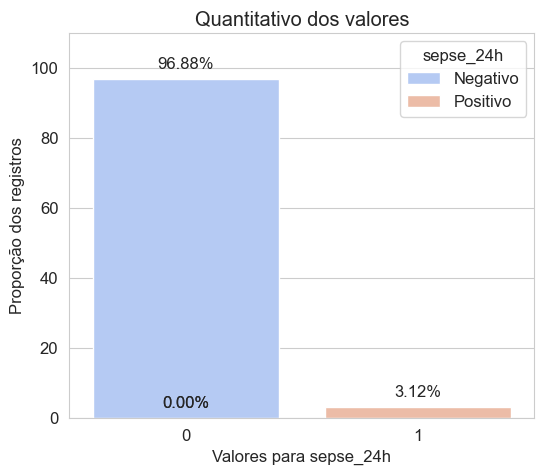

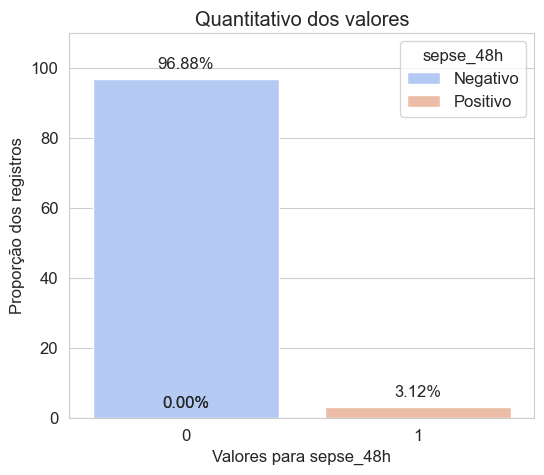

In [92]:
plota_proporcao(df_final24h, 'sepse_24h')
plota_proporcao(df_final48h, 'sepse_48h')

# Agrupa novamente criando novas feature

In [93]:

# ==========================
# 24H
# ==========================

y_col_24h = 'sepse_24h'

leak_columns = ['week',  'qtty_days']


cols_static24 = [   'cutoff24h', 'sepse_24h', 'total_days_observed', 'capillary_decreased','capillary_increased','capillary_none','capillary_normal',
                    'art_pressure_absent','art_pressure_present','art_pressure_weak', 'pulse_absent','pulse_present','pulse_weak'
                ]

cols_clinical24 = [
    c for c in df_final24h.columns
    if c not in ['person_id'] + cols_static24 + leak_columns
    and np.issubdtype(df_final24h[c].dtype, np.number)
]

agg_dict24 = {}

for col in cols_static24:
    agg_dict24[col] = (col, 'max')

for col in cols_clinical24:
    agg_dict24[f"{col}_last"] = (col, last_not_null)
    agg_dict24[f"{col}_mean"] = (col, "mean")
    agg_dict24[f"{col}_std"]  = (col, "std")
    agg_dict24[f"{col}_max"]  = (col, "max")
    agg_dict24[f"{col}_min"]  = (col, "min")

df_final24h = (
    df_final24h
    .groupby('person_id')
    .agg(**agg_dict24)
    .reset_index()
)

# ==========================
# 48H
# ==========================

y_col_48h = 'sepse_48h'

leak_columns = ['week',  'qtty_days']


cols_static48 = [   'cutoff48h', 'sepse_48h', 'total_days_observed', 'capillary_decreased','capillary_increased','capillary_none','capillary_normal',
                    'art_pressure_absent','art_pressure_present','art_pressure_weak', 'pulse_absent','pulse_present','pulse_weak'
                ]

cols_clinical48 = [
    c for c in df_final48h.columns
    if c not in ['person_id'] + cols_static48 + leak_columns
    and np.issubdtype(df_final48h[c].dtype, np.number)
]

agg_dict48 = {}

for col in cols_static48:
    agg_dict48[col] = (col, 'max')

for col in cols_clinical48:
    agg_dict48[f"{col}_last"] = (col, last_not_null)
    agg_dict48[f"{col}_mean"] = (col, "mean")
    agg_dict48[f"{col}_std"]  = (col, "std")
    agg_dict48[f"{col}_max"]  = (col, "max")
    agg_dict48[f"{col}_min"]  = (col, "min")

df_final48h = (
    df_final48h
    .groupby('person_id')
    .agg(**agg_dict48)
    .reset_index()
)

print(f"\nDF 24h: {df_final24h.shape}")
print(f"Count of Person IDs 24h: {len(df_final24h['person_id'].unique())}")

print(f"\nDF 48h: {df_final48h.shape}")
print(f"Count of Person IDs 48h: {len(df_final48h['person_id'].unique())}")


DF 24h: (2625, 214)
Count of Person IDs 24h: 2625

DF 48h: (2625, 214)
Count of Person IDs 48h: 2625


In [94]:
df_demographics = df_demographics.drop_duplicates(subset=['person_id'], keep='last')

df_final24h = df_final24h.merge(df_demographics, on='person_id', how='left').drop(columns=['datetime', 'birth_datetime', 'cutoff24h'])
df_final48h = df_final48h.merge(df_demographics, on='person_id', how='left').drop(columns=['datetime', 'birth_datetime', 'cutoff48h'])

# Verifica linhas duplicadas
df_final24h['person_id'].value_counts().loc[lambda x: x > 1]

Series([], Name: count, dtype: int64)

# APAGA MISSING ACIMA DE 70%

In [95]:
miss24 = (((df_final24h.isna().sum() / df_final24h.shape[0])) * 100).sort_values(ascending=False)
to_drop24h = list(miss24[miss24.values>=70.00].index.values)

# miss48 = (((df_final48h.isna().sum() / df_final48h.shape[0])) * 100).sort_values(ascending=False)
# to_drop48h = list(miss48[miss48.values>=95.00].index.values)

df_final24h = df_final24h.drop(columns=to_drop24h, errors='ignore').copy()
# df_final48h = df_final48h.drop(columns=to_drop48h, errors='ignore').copy()

print("Colunas Dropadas Base 24h !!!")
print(f"to_drop24h: {len(to_drop24h)}\n")
print(" - - - - ")
print(f"Shape 24h: {df_final24h.shape}\n")

Colunas Dropadas Base 24h !!!
to_drop24h: 108

 - - - - 
Shape 24h: (2625, 108)



In [96]:
miss48 = (((df_final48h.isna().sum() / df_final48h.shape[0])) * 100).sort_values(ascending=False)
to_drop48h = list(miss48[miss48.values>=70.00].index.values)

# miss48 = (((df_final48h.isna().sum() / df_final48h.shape[0])) * 100).sort_values(ascending=False)
# to_drop48h = list(miss48[miss48.values>=95.00].index.values)

df_final48h = df_final48h.drop(columns=to_drop48h, errors='ignore').copy()
# df_final48h = df_final48h.drop(columns=to_drop48h, errors='ignore').copy()

print("Colunas Dropadas Base 48h !!!")
print(f"to_drop48h: {len(to_drop48h)}\n")
print(" - - - - ")
print(f"Shape 48h: {df_final48h.shape}\n")

Colunas Dropadas Base 48h !!!
to_drop48h: 108

 - - - - 
Shape 48h: (2625, 108)



# SEPARACAO PARA NAO SUPERVISIONADO

In [97]:
from sklearn.decomposition import PCA
from scipy.spatial.distance import cdist, pdist
from matplotlib import pylab

In [98]:
X_cp48 = df_final48h[df_final48h['sepse_48h']==1][['lactate_mean', 'c_reactive_protein_mean', 'procalcitonin_mean', 'base_excess_venous_mean', 'glasgow_mean']].copy() #.drop(columns=['person_id', 'sepse_48h']) #, 'cluster_name'

X_48h = df_final48h.drop(columns=['person_id', 'sepse_48h'])
y_48h = df_final48h['sepse_48h']


# keep_cols = [c for c in X_48h.columns if c.endswith('_mean')]

X_not_missing = X_cp48.loc[:, X_cp48.isna().mean() < 0.65]

# Cria FLAG
for col in X_cp48.columns:
    X_cp48[col+'_measured'] = (~X_cp48[col].isna()).astype(int)
    X_cp48[col] = X_cp48[col].fillna(X_cp48[col].median())


In [99]:
# list(df_final24h.columns)
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_cp48)
kmean = KMeans(n_clusters=3, random_state=SEED)
clusters = kmean.fit_predict(X_scaled)


Componentes para 90%: 2
Componentes para 95%: 2
Componentes para 99%: 2


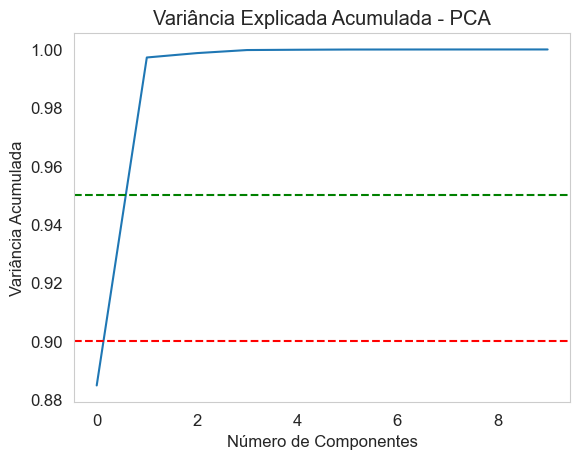

In [100]:
import numpy as np

pca_full = PCA().fit(X_cp48)
cum_var = np.cumsum(pca_full.explained_variance_ratio_)

n_90 = np.argmax(cum_var >= 0.90) + 1
n_95 = np.argmax(cum_var >= 0.95) + 1
n_99 = np.argmax(cum_var >= 0.99) + 1

print("Componentes para 90%:", n_90)
print("Componentes para 95%:", n_95)
print("Componentes para 99%:", n_99)

import matplotlib.pyplot as plt

plt.plot(cum_var)
plt.axhline(0.90, color='r', linestyle='--')
plt.axhline(0.95, color='g', linestyle='--')
plt.xlabel("Número de Componentes")
plt.ylabel("Variância Acumulada")
plt.title("Variância Explicada Acumulada - PCA")
plt.grid()
plt.show()

Text(0.5, 1.0, 'Variância Explicada vs Valor de K')

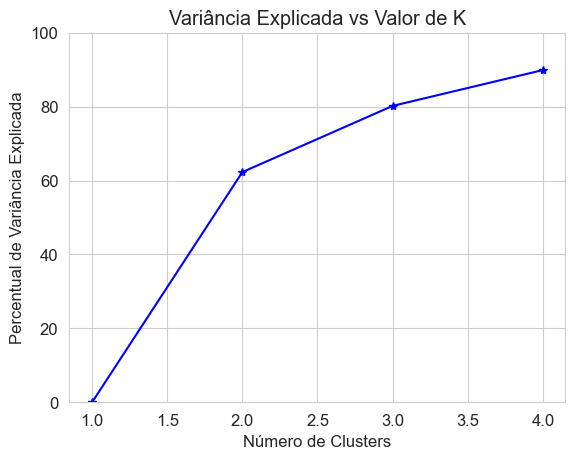

In [101]:
K_range = range(1,5)
pca = PCA(n_components=4).fit_transform(X_cp48) #.sample(frac=0.5)


#Aplicando 
k_means_cpa = [KMeans(n_clusters=k).fit(pca) for k in K_range]

centroides = [X.cluster_centers_ for X in k_means_cpa]

#Calculando distância euclidiana
k_euclid = [cdist(pca, cent, 'euclidean') for cent in centroides]
dist = [np.min(ke, axis=1) for ke in k_euclid]

# Soma dos quadrados das distâncias dentro do cluster
soma_quadrados_intra_cluster = [sum(d**2) for d in dist]

soma_total = sum(pdist(pca)**2/pca.shape[0])

# Soma dos quadrados entre clusters 
soma_quadrados_inter_cluster = soma_total - soma_quadrados_intra_cluster

# Curva de Ebow
fig = plt.figure()
ax = fig.add_subplot(111)
ax.plot(K_range, (soma_quadrados_inter_cluster/soma_total) * 100, 'b*-')
ax.set_ylim(0, 100)
plt.grid(True)
plt.xlabel('Número de Clusters')
plt.ylabel('Percentual de Variância Explicada')
plt.title('Variância Explicada vs Valor de K')

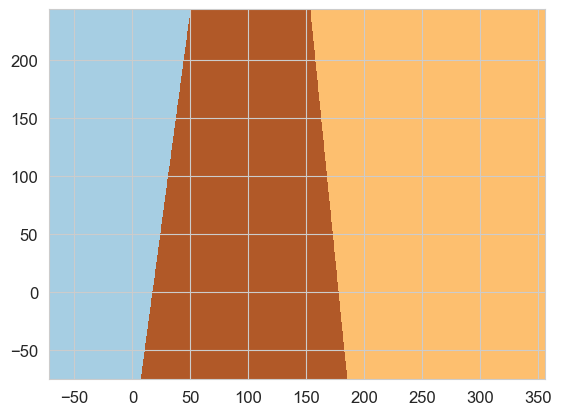

In [102]:

n = 3
modelo_v1 = KMeans(n_clusters=n)

pca = PCA(n_components=2).fit_transform(X_cp48)
modelo_v1.fit(pca)

# Obtem os valores mínimos e máximos e organiza o shape
x_min, x_max = pca[:, 0].min() - 5, pca[:, 0].max() - 1
y_min, y_max = pca[:, 1].min() + 1, pca[:,1].max() + 5
xx, yy = np.meshgrid(np.arange(x_min, x_max, 0.2), np.arange(y_min, y_max, 0.2))
Z = modelo_v1.predict(np.c_[xx.ravel(), yy.ravel()])
Z = Z.reshape(xx.shape) 

#Plot das áreas dos clusters
plt.figure(1)
plt.clf()
plt.imshow(
    Z,
    interpolation='nearest',
    extent=(xx.min(), xx.max(), yy.min(), yy.max()),
    cmap=plt.cm.Paired,
    aspect='auto',
    origin='lower'

)

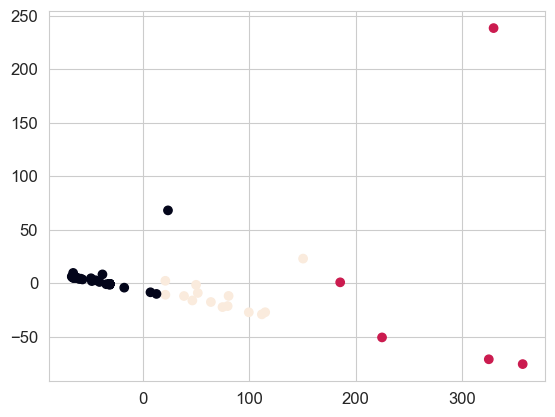

In [103]:
plt.scatter(pca[:, 0], pca[:, 1], c=modelo_v1.labels_)

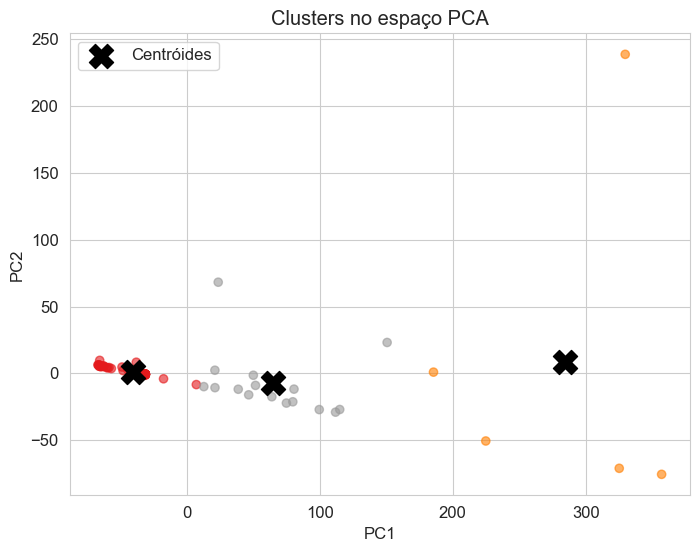

In [104]:
import matplotlib.pyplot as plt
import numpy as np
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans

# PCA 2D para visualização
pca = PCA(n_components=5)
X_pca = pca.fit_transform(X_cp48)

# KMeans
kmeans = KMeans(n_clusters=3, random_state=42)
labels = kmeans.fit_predict(X_pca)

centroids = kmeans.cluster_centers_

plt.figure(figsize=(8,6))

# Plot dos pontos
scatter = plt.scatter(
    X_pca[:,0],
    X_pca[:,1],
    c=labels,
    cmap='Set1',
    alpha=0.6
)

# Plot centróides
plt.scatter(
    centroids[:,0],
    centroids[:,1],
    s=300,
    c='black',
    marker='X',
    label='Centróides'
)

plt.xlabel('PC1')
plt.ylabel('PC2')
plt.title('Clusters no espaço PCA')
plt.legend()
plt.show()

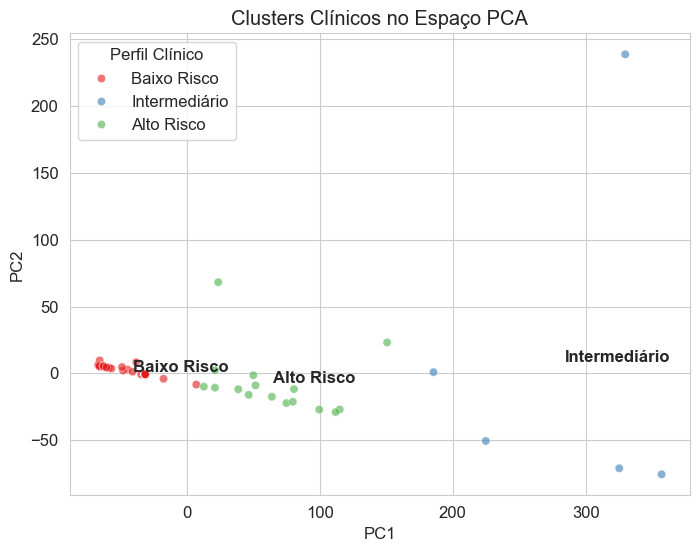

In [105]:
X_cp48['cluster'] = labels

cluster_profile = X_cp48.groupby('cluster').mean(numeric_only=True)
cluster_profile.T


cluster_names = {
    0: "Baixo Risco",
    1: "Intermediário",
    2: "Alto Risco"
}

X_cp48['cluster_name'] = X_cp48['cluster'].map(cluster_names)

import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(8,6))



sns.scatterplot(
    x=X_pca[:,0],
    y=X_pca[:,1],
    hue=X_cp48['cluster_name'],
    palette='Set1',
    alpha=0.6
)


for i, centroid in enumerate(centroids):
    plt.text(
        centroid[0],
        centroid[1],
        cluster_names[i],
        fontsize=12,
        weight='bold'
    )

plt.xlabel('PC1')
plt.ylabel('PC2')
plt.title('Clusters Clínicos no Espaço PCA')
plt.legend(title="Perfil Clínico")
plt.show()

In [106]:
X_cp48['cluster_name'].value_counts()

alto_risco_ids = X_cp48.loc[
    X_cp48['cluster_name'] == 'Alto Risco'
]

cluster_profile = X_cp48.groupby('cluster').mean(numeric_only=True)

# cluster_profile.T.sort_values(by=2, ascending=False).head(15)

# import numpy as np

# cluster_diff = cluster_profile.max() - cluster_profile.min()
# cluster_diff.sort_values(ascending=False).head(20)
cluster_profile

,lactate_mean,c_reactive_protein_mean,procalcitonin_mean,base_excess_venous_mean,glasgow_mean,lactate_mean_measured,c_reactive_protein_mean_measured,procalcitonin_mean_measured,base_excess_venous_mean_measured,glasgow_mean_measured
cluster,,,,,,,,,,
0,1.57,27.67,0.89,0.91,14.59,0.38,0.44,0.31,0.39,0.33
1,1.92,345.12,70.59,0.46,14.40,1.00,1.00,1.00,1.00,0.60
2,1.99,132.94,12.60,0.47,8.94,1.00,1.00,1.00,0.94,0.94


In [107]:
len(df_final48h[df_final48h['sepse_48h']==1]), len(clusters)

(82, 82)

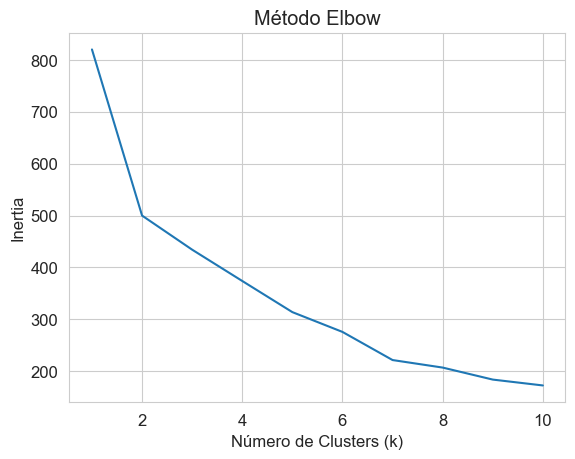

In [108]:
df_cluster = df_final48h[df_final48h['sepse_48h']==1].copy()
df_cluster['cluster'] = clusters


pd.crosstab(df_cluster['cluster'], df_cluster['sepse_48h'], normalize='index')

centroides = kmean.cluster_centers_

# centroids_original = scaler.inverse_transform(kmeans.cluster_centers_)

# centroids_df = pd.DataFrame(
#     centroids_original,
#     columns=X.columns
# )

# centroids_df

inertia = []
K_range = range(1, 11)

for k in K_range:
    km = KMeans(n_clusters=k, random_state=42)
    km.fit(X_scaled)
    inertia.append(km.inertia_)

plt.figure()
plt.plot(K_range, inertia)
plt.xlabel("Número de Clusters (k)")
plt.ylabel("Inertia")
plt.title("Método Elbow")
plt.show()


In [109]:
from sklearn.metrics import silhouette_score

for k in range(2, 8):
    km = KMeans(n_clusters=k, random_state=42)
    labels = km.fit_predict(X_scaled)
    score = silhouette_score(X_scaled, labels)
    print(f"k={k} → silhouette={score:.4f}")

k=2 → silhouette=0.4520
k=3 → silhouette=0.4578
k=4 → silhouette=0.4324
k=5 → silhouette=0.4468
k=6 → silhouette=0.4209
k=7 → silhouette=0.4448


In [110]:
labels_new = modelo_v1.labels_
silhouette_score(pca, labels_new, metric='euclidean')

InvalidParameterError: The 'X' parameter of silhouette_score must be an array-like or a sparse matrix. Got PCA(n_components=5) instead.

In [ ]:
err

In [111]:
pd.Series(kmeans.labels_).value_counts(dropna=False)

0    61
2    16
1     5
Name: count, dtype: int64

# SPLIT com stratify

In [112]:
from sklearn.model_selection import train_test_split

X_24h = df_final24h.drop(columns=['person_id', 'sepse_24h', 'total_days_observed'])
y_24h = df_final24h['sepse_24h']

# X_48h['cluster']= kmeans.labels_

X_train24h, X_test24h, y_train24h, y_test24h = train_test_split(
    X_24h,
    y_24h,
    test_size=0.3,
    random_state=SEED,
    stratify=y_24h  
)

# X_48h = df_final48h.drop(columns=['person_id', 'sepse_48h'])
# y_48h = df_final48h['sepse_48h']

X_train48h, X_test48h, y_train48h, y_test48h = train_test_split(
    X_48h,
    y_48h,
    test_size=0.3,
    random_state=SEED,
    stratify=y_48h  
)

In [113]:
err

NameError: name 'err' is not defined

In [ ]:
X_train24h.shape, y_train24h.shape, X_test24h.shape, y_test24h.shape, X_train48h.shape, y_train48h.shape, X_test48h.shape, y_test48h.shape

((1837, 105),
 (1837,),
 (788, 105),
 (788,),
 (1837, 106),
 (1837,),
 (788, 106),
 (788,))

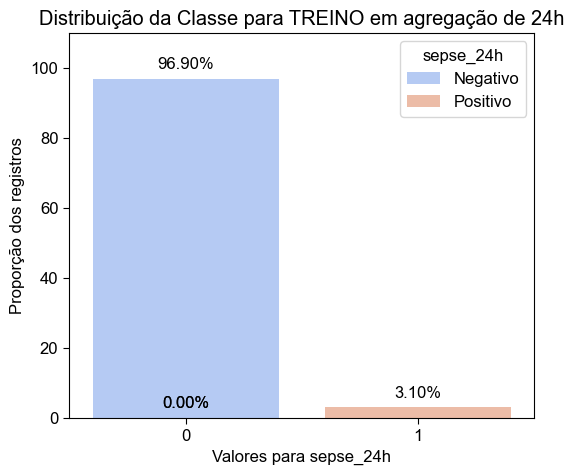

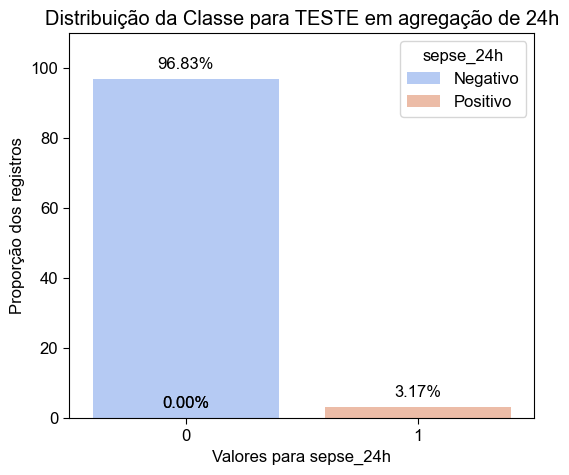

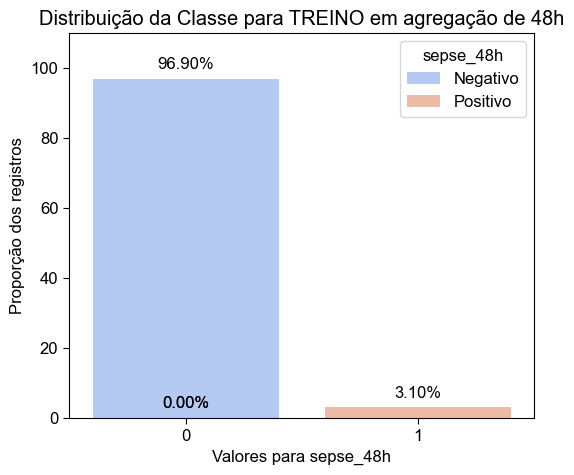

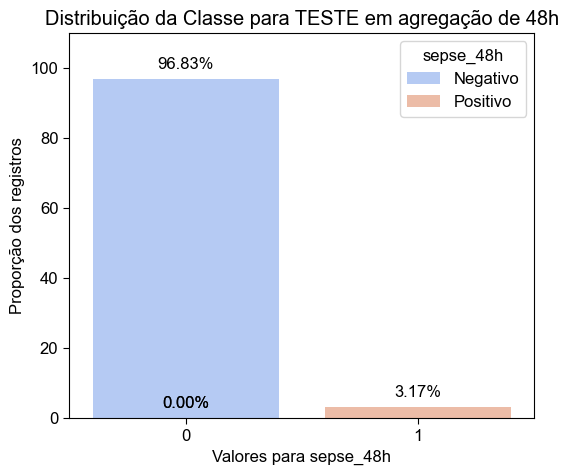

In [ ]:
plota_proporcao(pd.DataFrame(y_train24h), 'sepse_24h', "Distribuição da Classe para TREINO em agregação de 24h")
plota_proporcao(pd.DataFrame(y_test24h), 'sepse_24h', 'Distribuição da Classe para TESTE em agregação de 24h')
plota_proporcao(pd.DataFrame(y_train48h), 'sepse_48h', "Distribuição da Classe para TREINO em agregação de 48h")
plota_proporcao(pd.DataFrame(y_test48h), 'sepse_48h', 'Distribuição da Classe para TESTE em agregação de 48h')

# MODELOS

### Scales de acordo com a proporção das classes

In [ ]:
scale24h = ((y_train24h==0).sum()/(y_train24h==1).sum()) * 1.8
scale48h = ((y_train48h==0).sum()/(y_train48h==1).sum()) * 1.8

scale24h, scale48h 

(np.float64(56.21052631578947), np.float64(56.21052631578947))

### RandomSearchCV 

In [ ]:
from sklearn.ensemble import RandomForestClassifier
from lightgbm import LGBMClassifier
from xgboost import XGBClassifier
from catboost import CatBoostClassifier
from sklearn.ensemble import HistGradientBoostingClassifier

n_estimators=[300, 600, 1000]
max_depth=[2, 3, 4]
min_samples_leaf=[3, 7, 10]
class_weight=[{0:1, 1:30}, {0:1, 1:50}, {0:1, 1:100}]
boosting_type=["gbdt", "dart", "goss"] 
num_leaves=[20, 40]
learning_rate=[0.01, 0.03]
max_bin=[100, 200]
subsample=[0.6, 0.9]
colsample_bytree=[0.6, 0.9]
min_child_samples=[4, 8, 12]
reg_lambda=[1, 3]
min_split_gain=[0, 0.05, 0.1]
metric=['average_precision', 'recall']
max_iter=[300, 600, 1000]
max_leaf_nodes=[3, 30, 50]
scoring=['average_precision', 'recall']
eval_metric=['aucpr', 'logloss', 'recall']
scale_pos_weight=[30, 50, 100] #{0:1, 1:110},  #scale_pos,
iterations=[100, 1000]
class_weights=['Balanced', {0:1, 1:50}, {0:1, 1:100}]  #[{0:1, 1:150}]
l2_leaf_reg=[6, 10]
loss_function=['Logloss']
eval_metric_CAT=['PRAUC']


def build_models(scale_pos):
    return {
        # 'RF': RandomForestClassifier(
        #     random_state=SEED,
        #     n_jobs=6
        # ),
        # 'CAT': CatBoostClassifier( #CatBoostSklearnWrapper(
        #     random_seed=SEED,
        #     early_stopping_rounds=150,
        #     verbose=0
        # ),
        'LGBM': LGBMClassifier(
            objective='binary',
            random_state=SEED,
            n_jobs=6, 
            verbose=-1,
            error_score='raise'
        )        ,
        'HIST': HistGradientBoostingClassifier(
            random_state=SEED,
            early_stopping=True
        ),
        'XGB': XGBClassifier(
            objective='binary:logistic',
            random_state=SEED,
            n_jobs=6
        )
    }

param_spaces = {
    'RF': {
        'n_estimators': n_estimators,
        'max_depth': max_depth,
        'min_samples_leaf': min_samples_leaf,
        'class_weight': class_weight
        # 'max_features': max_fear
        }, 
    'LGBM': {
        'boosting_type': boosting_type,
        'n_estimators': n_estimators,
        'num_leaves': num_leaves,
        'learning_rate': learning_rate,
        'max_bin': max_bin,
        'subsample': subsample,
        'colsample_bytree': colsample_bytree,
        'min_child_samples': min_child_samples,
        'reg_lambda': reg_lambda,
        'min_split_gain': min_split_gain,
        'class_weight': class_weight,
        'metric': metric
        },
    'HIST': {
        'max_iter': max_iter,
        'max_leaf_nodes': max_leaf_nodes,
        'learning_rate': learning_rate,
        'max_depth': max_depth,
        'min_samples_leaf': min_samples_leaf,
        'class_weight': class_weight,
        'scoring': scoring
        }, 
    'XGB': {
        'n_estimators': n_estimators,
        'max_depth': max_depth,
        'learning_rate': learning_rate,
        'subsample': subsample,
        'colsample_bytree': colsample_bytree,
        'eval_metric': eval_metric,
        'scale_pos_weight': scale_pos_weight
        },
    'CAT': {
            'iterations':iterations,
            'depth': max_depth, 
            'learning_rate':learning_rate,
            'class_weights': class_weights,
            'l2_leaf_reg': l2_leaf_reg,
            'loss_function': loss_function,
            'eval_metric': eval_metric_CAT
        }
    } 


models24h = build_models(scale_pos=scale24h)
models48h = build_models(scale_pos=scale48h)
            #'eval_metric':'PRAUC',  # foco clínico
            #'eval_metric': 'AUC:PR',
            # auto_class_weights:'Balanced',

In [ ]:
df_rank_24h, best_models_24h, best_params_24h, best_thresholds_24h, best_name24h, best_model24h, best_score24h, best_estimator24h = val_cross(
    models24h,
    param_spaces,
    n_iter=5,
    X=X_train24h,
    y=y_train24h, x_teste=X_test24h, y_teste=y_test24h)

Início do modelo...
Hora Início...: 13:57h
Feitas validações cruzadas. N-Iter = 5
Métrica de avaliação - PR-AUC

🔍 Otimizando modelo: LGBM...
Hora Início..LGBM.: 13:57h
Hora FIM..LGBM.: 13:58h
✅ Melhor PR-AUC (CV): 0.3628
📌 Melhores parâmetros: {'subsample': 0.6, 'reg_lambda': 1, 'num_leaves': 40, 'n_estimators': 1000, 'min_split_gain': 0, 'min_child_samples': 12, 'metric': 'average_precision', 'max_bin': 200, 'learning_rate': 0.01, 'colsample_bytree': 0.6, 'class_weight': {0: 1, 1: 100}, 'boosting_type': 'goss'}

🔍 Otimizando modelo: HIST...
Hora Início..HIST.: 13:58h
Hora FIM..HIST.: 13:58h
✅ Melhor PR-AUC (CV): 0.1651
📌 Melhores parâmetros: {'scoring': 'average_precision', 'min_samples_leaf': 7, 'max_leaf_nodes': 3, 'max_iter': 300, 'max_depth': 4, 'learning_rate': 0.03, 'class_weight': {0: 1, 1: 50}}

🔍 Otimizando modelo: XGB...
Hora Início..XGB.: 13:58h
Hora FIM..XGB.: 13:58h
✅ Melhor PR-AUC (CV): 0.3266
📌 Melhores parâmetros: {'subsample': 0.9, 'scale_pos_weight': 50, 'n_estimato

In [ ]:
df_rank_48h, best_models_48h, best_params_48h, best_thresholds_48h, best_name48h, best_model48h, best_score48h, best_estimator48h = val_cross(
    models48h,
    param_spaces,
    n_iter=5,
    X=X_train48h,
    y=y_train48h, x_teste=X_test48h, y_teste=y_test48h)

Início do modelo...
Hora Início...: 13:58h
Feitas validações cruzadas. N-Iter = 5
Métrica de avaliação - PR-AUC

🔍 Otimizando modelo: LGBM...
Hora Início..LGBM.: 13:58h
Hora FIM..LGBM.: 13:59h
✅ Melhor PR-AUC (CV): 0.6034
📌 Melhores parâmetros: {'subsample': 0.6, 'reg_lambda': 1, 'num_leaves': 40, 'n_estimators': 1000, 'min_split_gain': 0, 'min_child_samples': 12, 'metric': 'average_precision', 'max_bin': 200, 'learning_rate': 0.01, 'colsample_bytree': 0.6, 'class_weight': {0: 1, 1: 100}, 'boosting_type': 'goss'}

🔍 Otimizando modelo: HIST...
Hora Início..HIST.: 13:59h
Hora FIM..HIST.: 13:59h
✅ Melhor PR-AUC (CV): 0.3869
📌 Melhores parâmetros: {'scoring': 'average_precision', 'min_samples_leaf': 7, 'max_leaf_nodes': 3, 'max_iter': 300, 'max_depth': 4, 'learning_rate': 0.03, 'class_weight': {0: 1, 1: 50}}

🔍 Otimizando modelo: XGB...
Hora Início..XGB.: 13:59h
Hora FIM..XGB.: 13:59h
✅ Melhor PR-AUC (CV): 0.5852
📌 Melhores parâmetros: {'subsample': 0.9, 'scale_pos_weight': 50, 'n_estimato

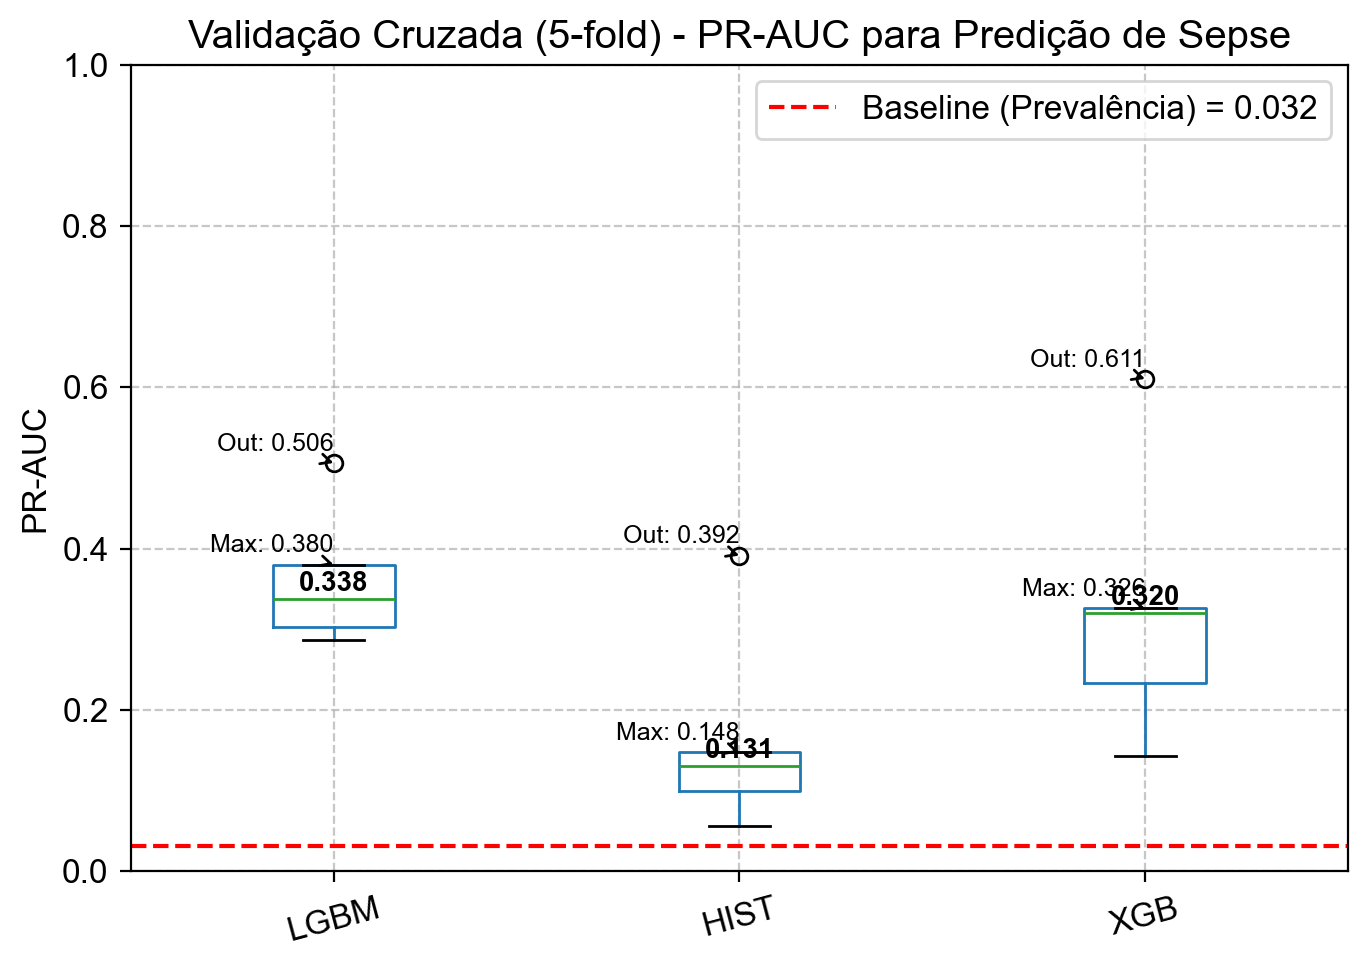

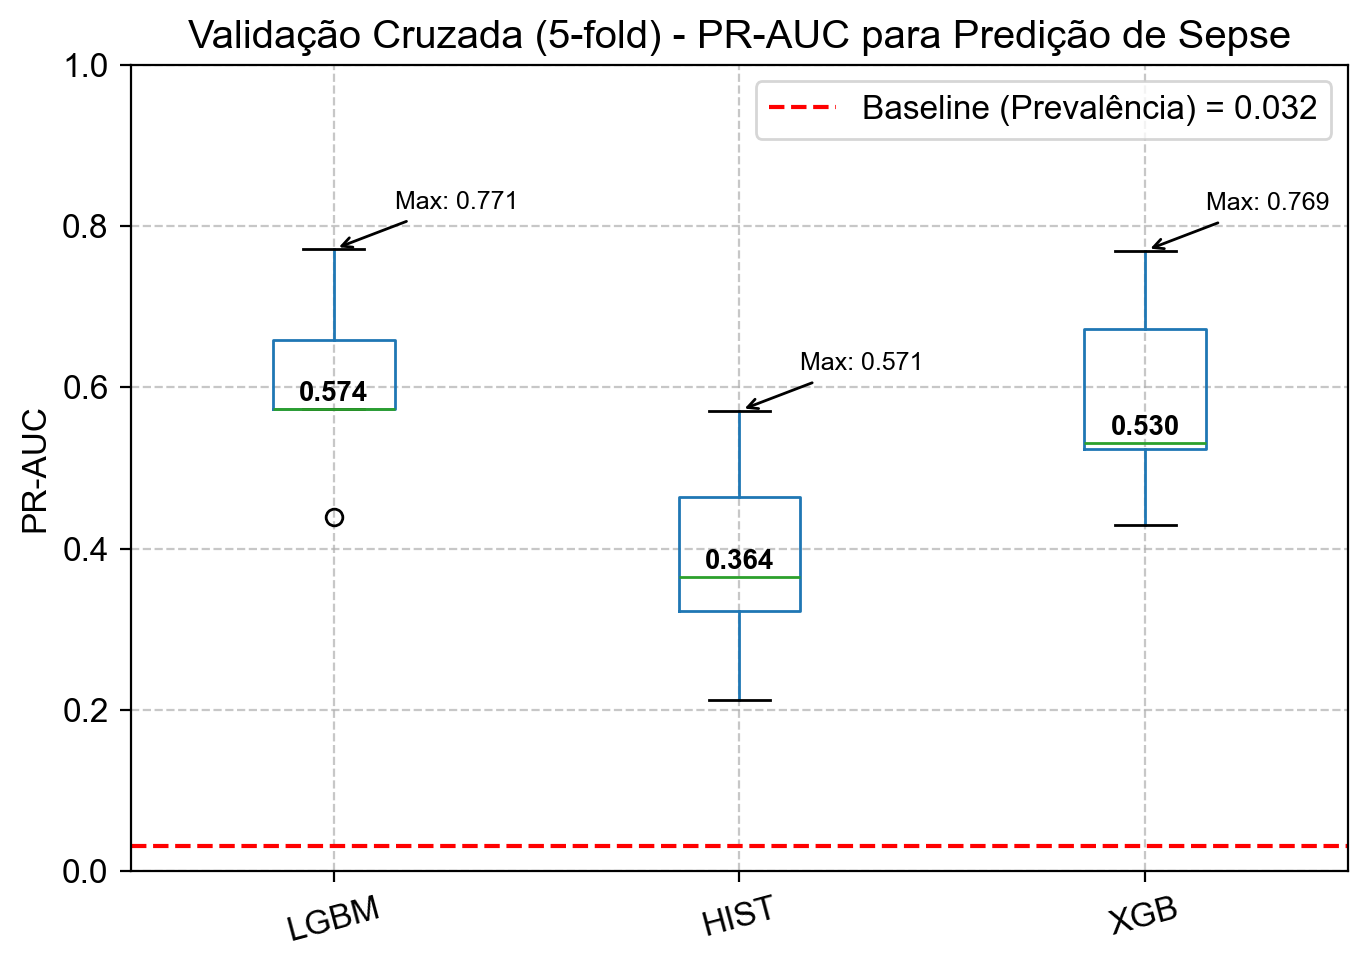

In [ ]:
plota_resultados_boxplot(df_rank_24h, y_test24h, figsize=(7,5), dpis=200)
plota_resultados_boxplot(df_rank_48h, y_test48h, figsize=(7,5), dpis=200)

In [ ]:
print(f"Melhor PR-AUC 24h Treino: {best_score24h}, \nMelhor PR-AUC 24h Teste:{average_precision_score(y_test24h.values, best_estimator24h.predict_proba(X_test24h)[:,1])}")
print('')
print(f"Melhor PR-AUC 48h Treino: {best_score48h}, \nMelhor PR-AUC 48h Teste:{average_precision_score(y_test48h.values, best_estimator48h.predict_proba(X_test48h)[:,1])}")


Melhor PR-AUC 24h Treino: 0.3628316191908885, 
Melhor PR-AUC 24h Teste:0.49189493351335656

Melhor PR-AUC 48h Treino: 0.6034182108930315, 
Melhor PR-AUC 48h Teste:0.7514024686588755


# RESULTADOS !!

In [ ]:
# Probabilidades 24h
y_prob24 = best_estimator24h.predict_proba(X_test24h)[:, 1]
precision24, recall24, thresholds24 = precision_recall_curve(y_test24h, y_prob24)
pr_auc24 = average_precision_score(y_test24h, y_prob24)
y_pred24 = best_estimator24h.predict(X_test24h)

# Probabilidades 48
y_prob48 = best_estimator48h.predict_proba(X_test48h)[:, 1]
precision48, recall48, thresholds48 = precision_recall_curve(y_test48h, y_prob48)
pr_auc48 = average_precision_score(y_test48h, y_prob48)
y_pred48 = best_estimator48h.predict(X_test48h)


In [ ]:
import numpy as np
from sklearn.metrics import precision_score, recall_score

thresholds = np.linspace(0, 1, 2000)

best_t = None
best_recall = 0

for t in thresholds:
    y_pred = (y_prob48 >= t).astype(int)
    rec = recall_score(y_test48h, y_pred)
    prec = precision_score(y_test48h, y_pred, zero_division=0)
    
    # critério clínico
    if prec >= 0.25:
        if rec > best_recall:
            best_recall = rec
            best_t = t

best_t, best_recall

(np.float64(0.013006503251625811), 0.84)

[[701  62]
 [  4  21]]


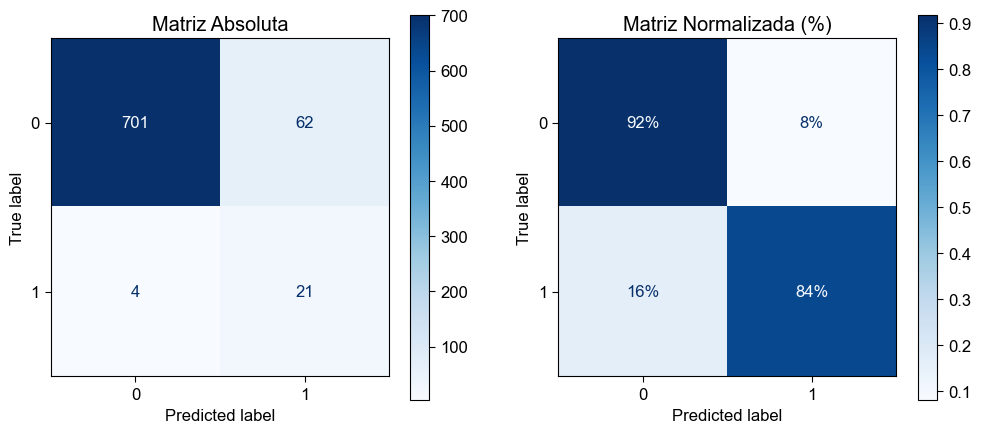

In [ ]:

threshold = best_t #0.0152  # exemplo
y_pred = (y_prob48 >= threshold).astype(int)

cm = confusion_matrix(y_test48h, y_pred)

print(cm)
plota_confusion_matrix(y_test48h, y_pred)
# plota_confusion_matrix(y_test48h, y_pred48)


In [ ]:
from sklearn.metrics import f1_score

best_f1 = 0
best_t = 0

for t in thresholds:
    y_pred = (y_prob24 >= t).astype(int)
    f1 = f1_score(y_test24h, y_pred)
    
    if f1 > best_f1:
        best_f1 = f1
        best_t = t

best_t, best_f1

(np.float64(0.8459229614807403), 0.5263157894736842)

# TODO:

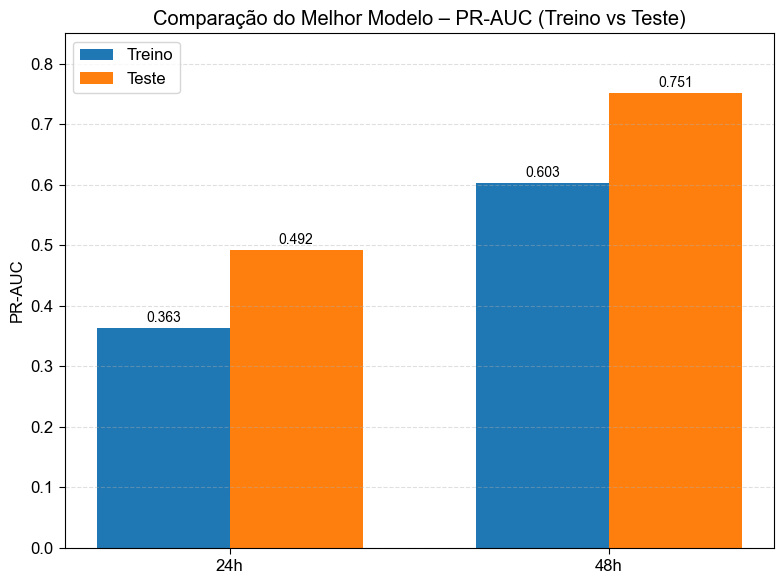

In [ ]:
#GRAFICO
# Dados
labels = ['24h', '48h']
train_scores = [best_score24h, best_score48h]
test_scores  = [pr_auc24, pr_auc48]

x = np.arange(len(labels))
width = 0.35

plt.figure(figsize=(8,6))

bars1 = plt.bar(x - width/2, train_scores, width, label='Treino')
bars2 = plt.bar(x + width/2, test_scores,  width, label='Teste')

# Anotar valores nas barras
for bar in bars1 + bars2:
    height = bar.get_height()
    plt.text(
        bar.get_x() + bar.get_width()/2,
        height + 0.01,
        f'{height:.3f}',
        ha='center',
        fontsize=10
    )

plt.xticks(x, labels)
plt.ylabel('PR-AUC')
plt.title('Comparação do Melhor Modelo – PR-AUC (Treino vs Teste)')
plt.ylim(0, 0.85)
plt.legend()
plt.grid(axis='y', linestyle='--', alpha=0.4)

plt.tight_layout()
plt.show()

# PR-AUC / ROC-AUC

In [ ]:
import numpy as np
from sklearn.metrics import precision_recall_curve



# Remover último ponto (não possui threshold correspondente)
precision24 = precision24[:-1]
recall24 = recall24[:-1]

target_recall = 0.75

# Índices que satisfazem recall >= 0.80
valid_idx24 = np.where(recall24 >= target_recall)[0]

# Escolher o MAIOR threshold possível (mais conservador)
best_idx24 = valid_idx24[-1]

best_threshold24 = thresholds24[best_idx24]

print("Threshold escolhido 24h:", best_threshold24)
print("Recall obtido: 24h", recall24[best_idx24])
print("Precision obtida: 24h", precision24[best_idx24])

##################################################################################################################



# Remover último ponto (não possui threshold correspondente)
precision48 = precision48[:-1]
recall48 = recall48[:-1]

target_recall = target_recall

# Índices que satisfazem recall >= 0.80
valid_idx48 = np.where(recall48 >= target_recall)[0]

# Escolher o MAIOR threshold possível (mais conservador)
best_idx48 = valid_idx48[-1]

best_threshold48 = thresholds48[best_idx48]

print("Threshold escolhido 48h:", best_threshold48)
print("Recall obtido: 48h", recall48[best_idx48])
print("Precision obtida: 48h", precision48[best_idx48])

Threshold escolhido 24h: 0.009803508444040302
Recall obtido: 24h 0.76
Precision obtida: 24h 0.14615384615384616
Threshold escolhido 48h: 0.06796900852951103
Recall obtido: 48h 0.76
Precision obtida: 48h 0.4222222222222222


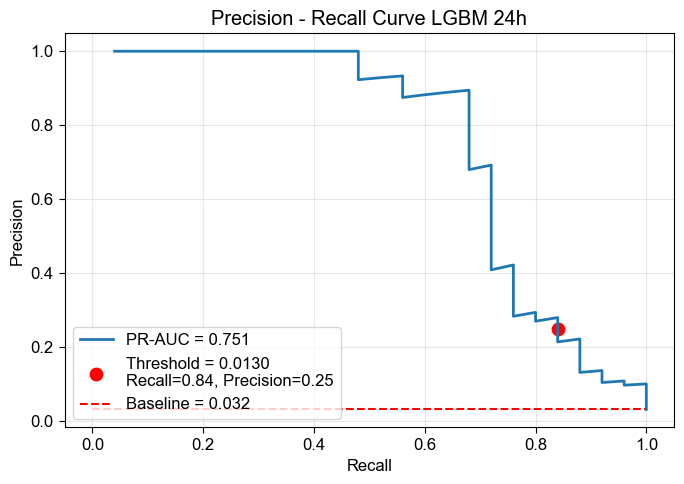

In [ ]:

best_thresholds_48h = threshold

# Encontrar índice do threshold mais próximo 48
idx_thr48 = np.argmin(np.abs(thresholds48 - best_thresholds_48h))

rec_thr48 = recall48[idx_thr48]
prec_thr48 = precision48[idx_thr48]

plt.figure(figsize=(7,5))

plt.plot(recall48, precision48, linewidth=2, label=f'PR-AUC = {pr_auc48:.3f}')

# marcar threshold clínico real 
plt.scatter(rec_thr48, prec_thr48, color='red', s=80,
            label=f'Threshold = {best_thresholds_48h:.4f}\nRecall={rec_thr48:.2f}, Precision={prec_thr48:.2f}')


baseline48 = y_test48h.mean()
plt.hlines(baseline48, 0, 1, linestyles='dashed', label=f'Baseline = {baseline48:.3f}', colors='red')


plt.xlabel('Recall')
plt.ylabel('Precision')
plt.title(f'Precision - Recall Curve {best_name48h} 24h')
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

Melhor threshold: 0.010053899268250151
Recall: 0.72
Precision: 0.140625


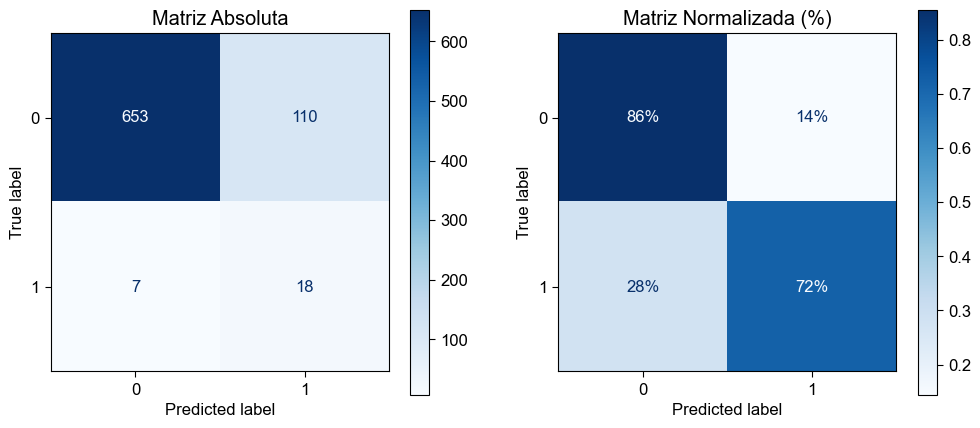

In [ ]:
#precision, recall, thresholds = precision_recall_curve(y_test24h, y_prob_24)

# encontrar primeiro threshold que atinja recall >= 0.70
idx = np.where(recall24 >= .70)[0]

if len(idx) > 0:
    best_idx = idx[-1]   # maior threshold possível mantendo recall
    best_threshold = thresholds24[best_idx]
else:
    best_threshold = thresholds24[0]

y_pred_opt24 = (y_prob24 >= best_threshold).astype(int)

print("Melhor threshold:", best_threshold)
print("Recall:", recall24[best_idx])
print("Precision:", precision24[best_idx])

# GERADO COM RECALL > 0.8
y_pred_opt24 = (y_prob24 >= best_threshold).astype(int)
plota_confusion_matrix(y_test24h, y_pred_opt24)

### ⚠️ Correção (pós-defesa)
A versão original desta célula imprimia recall/precisão usando um índice (`best_idx`) herdado da célula anterior (curva de **24h**), e não o threshold de **48h**. As linhas antigas foram mantidas comentadas.

Com o threshold de **0,0130** (célula de busca acima), os valores corretos — consistentes com a matriz de confusão (TN 701 · FP 62 · FN 4 · TP 21) e com `plota_calculate_metrics` na célula seguinte — são:

| Métrica | Valor |
|---|---|
| Recall (sensibilidade) | **0,84** |
| Precisão | **0,253** |
| Especificidade | 0,919 |
| ROC-AUC | 0,959 |
| PR-AUC (AP) | 0,751 |

*A saída impressa antiga desta célula foi removida por vir das linhas erradas; reexecute o notebook para regenerá-la.*

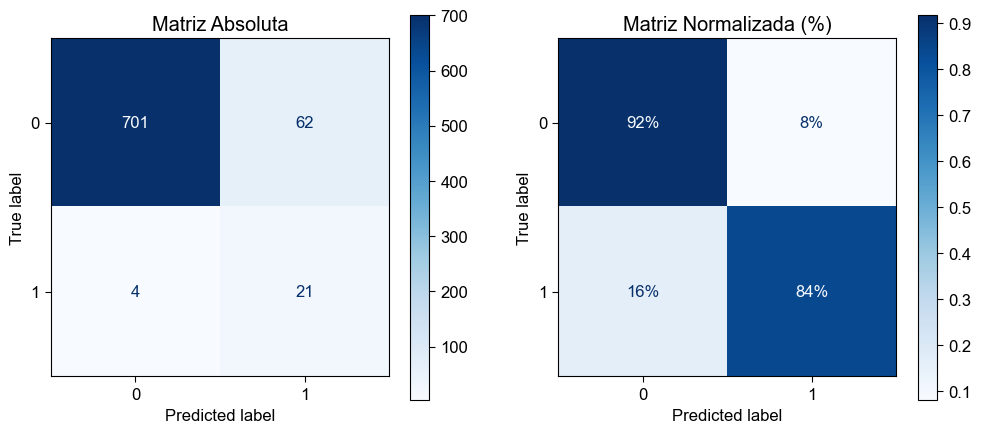

In [ ]:
# # encontrar primeiro threshold que atinja recall >= 0.70
# TARGET_RECALL = 0.7
# idx = np.where(recall48 >= TARGET_RECALL)[0]

# if len(idx) > 0:
#     best_idx = idx[-1]   # maior threshold possível mantendo recall
#     best_threshold = thresholds[best_idx]
# else:
#     best_threshold = thresholds[0]
best_threshold = threshold
y_pred_opt48 = (y_prob48 >= best_threshold).astype(int)

print("Melhor threshold:", best_threshold)
# [CORRIGIDO] As duas linhas abaixo estavam ERRADAS: usavam "best_idx", que sobrou da célula anterior
# (calculado na curva de 24h). Assim, recall/precision impressos NÃO correspondiam ao threshold de 48h.
# Foi daí que saiu o "Recall 0.72 / Precision 0.69" citado na monografia.
# print("Recall:", recall48[best_idx])
# print("Precision:", precision48[best_idx])

# Forma correta: calcular as métricas a partir das predições feitas com o threshold escolhido
y_pred_opt48 = (y_prob48 >= best_threshold).astype(int)
print("Recall:", recall_score(y_test48h, y_pred_opt48))        # 0.84  (21/25)
print("Precision:", precision_score(y_test48h, y_pred_opt48))  # 0.253 (21/83)

# GERADO COM RECALL > 0.8
y_pred_opt48 = (y_prob48 >= best_threshold).astype(int)
plota_confusion_matrix(y_test48h, y_pred_opt48)

In [ ]:
plota_calculate_metrics(y_test48h, y_pred_opt48, y_prob48)

{'ROC_AUC': 0.9587942332896462,
 'PR_AUC': 0.7494725770955825,
 'Average_Precision': 0.7514024686588755,
 'F1_Score': 0.3888888888888889,
 'Balanced_Accuracy': 0.8793709043250327,
 'MCC': 0.4332042255019887,
 'Specificity': np.float64(0.9187418086500655),
 'Sensitivity': np.float64(0.84),
 'Precision': 0.25301204819277107,
 'Recall': 0.84}

In [ ]:
plota_calculate_metrics(y_test48h, y_pred_opt48, y_prob48)

{'ROC_AUC': 0.9587942332896462,
 'PR_AUC': 0.7494725770955825,
 'Average_Precision': 0.7514024686588755,
 'F1_Score': 0.3888888888888889,
 'Balanced_Accuracy': 0.8793709043250327,
 'MCC': 0.4332042255019887,
 'Specificity': np.float64(0.9187418086500655),
 'Sensitivity': np.float64(0.84),
 'Precision': 0.25301204819277107,
 'Recall': 0.84}

# AUC

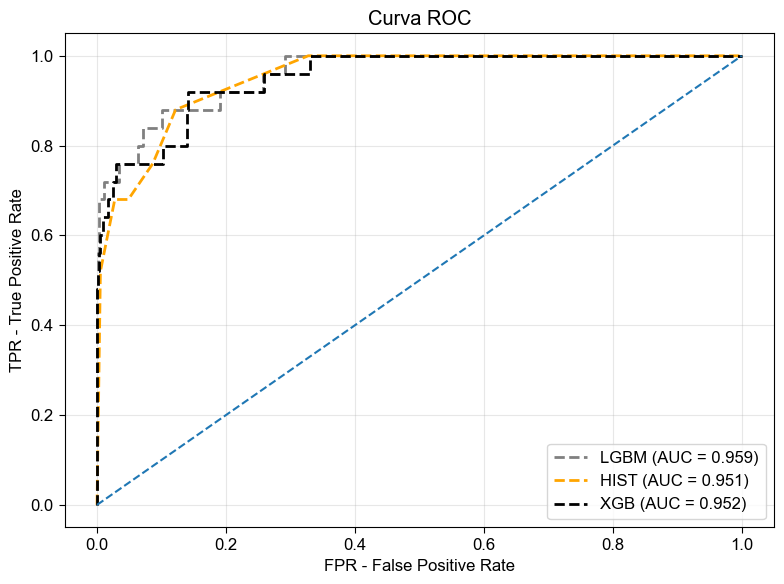

In [ ]:
import matplotlib.pyplot as plt
from sklearn.metrics import roc_curve, roc_auc_score

# Dicionário com modelos já treinados
# models = {
#     "LightGBM": lgbm_model,
#     "HistGradientBoost": hist_model,
#     "RandomForest": rf_model,
#     "XGBoost": xgb_model
# }

models = best_models_48h



plt.figure(figsize=(8,6))
colors = {
    "LGBM": "gray",
    "HIST": "orange",
    # "RandomForest": "green",
    "XGB": "black"
}
for nome, model in models.items():
    
    y_prob = model.predict_proba(X_test48h)[:, 1]
    
    fpr, tpr, _ = roc_curve(y_test48h, y_prob)
    roc_auc = roc_auc_score(y_test48h, y_prob)
    
    plt.plot(
        fpr,
        tpr,
        linestyle='--',
        linewidth=2,
        color=colors[nome],
        label=f'{nome} (AUC = {roc_auc:.3f})'
    )

# Linha diagonal (modelo aleatório)
plt.plot([0,1], [0,1], linestyle='--')

plt.xlabel('FPR - False Positive Rate')
plt.ylabel('TPR - True Positive Rate')
plt.title('Curva ROC')
plt.legend()
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()

In [ ]:
# plota_calculate_metrics(y_test24h, y_pred_24)

0.013006503251625811

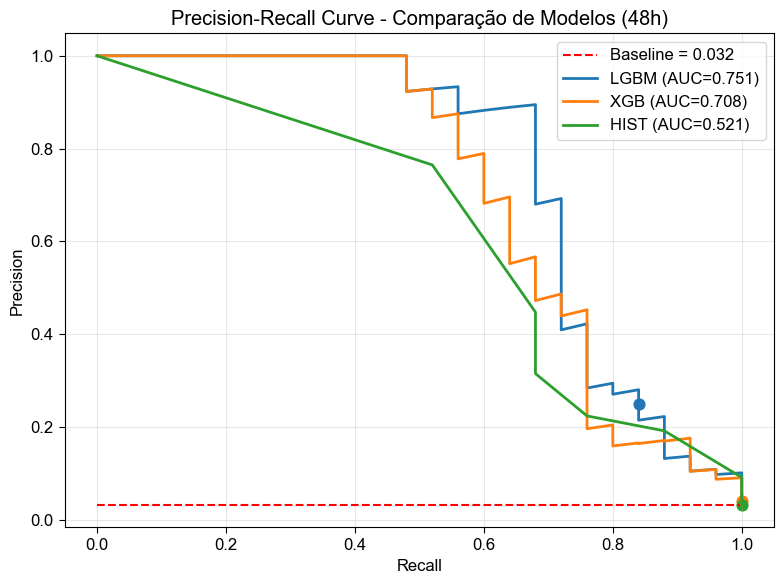

In [ ]:
from sklearn.metrics import precision_recall_curve, average_precision_score

plt.figure(figsize=(8,6))

baseline = y_test48h.mean()
plt.hlines(
    baseline, 0, 1,
    linestyles='dashed',
    colors='red',
    label=f'Baseline = {baseline:.3f}'
)

results_plot = []

for nome, model in best_models_48h.items():

    model.fit(X_train48h, y_train48h)
    y_prob = model.predict_proba(X_test48h)[:, 1]

    precision, recall, thresholds = precision_recall_curve(y_test48h, y_prob)
    pr_auc = average_precision_score(y_test48h, y_prob)

    results_plot.append((nome, pr_auc, precision, recall, thresholds))

# 🔥 Ordenar por PR-AUC (melhor primeiro)
results_plot = sorted(results_plot, key=lambda x: x[1], reverse=True)

for nome, pr_auc, precision, recall, thresholds in results_plot:

    plt.plot(
        recall,
        precision,
        linewidth=2,
        label=f'{nome} (AUC={pr_auc:.3f})'
    )

    # marcar threshold específico do modelo
    best_thr = float(best_thresholds_48h)

    idx_thr = np.argmin(np.abs(thresholds - best_thr))

    rec_thr = recall[idx_thr]
    prec_thr = precision[idx_thr]

    plt.scatter(
        rec_thr,
        prec_thr,
        s=60
    )

plt.xlabel('Recall')
plt.ylabel('Precision')
plt.title('Precision-Recall Curve - Comparação de Modelos (48h)')
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

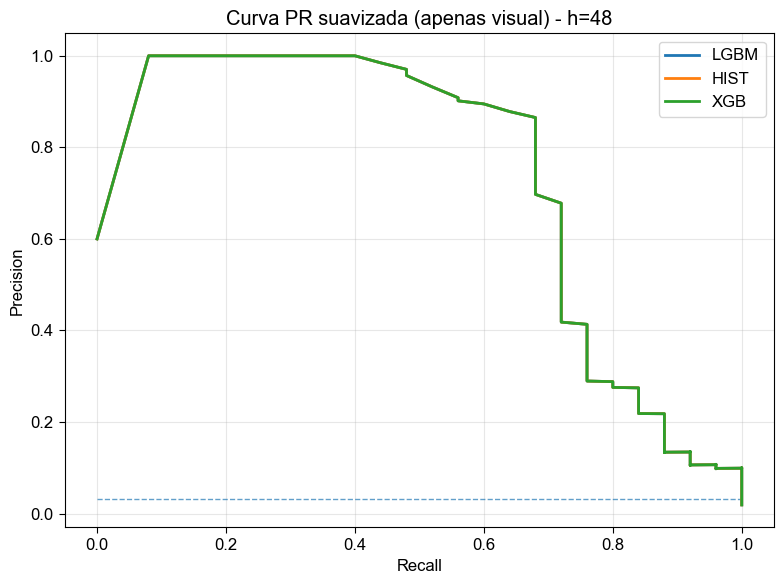

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import precision_recall_curve

plt.figure(figsize=(8,6))

baseline = y_test24h.mean()
plt.hlines(
    baseline, 0, 1,
    linestyle='--',
    linewidth=1,
    alpha=0.7
)

for nome, model in best_models_24h.items():

    #y_prob_48 = model.predict_proba(X_test48h)[:, 1]

    precision, recall, _ = precision_recall_curve(y_test48h, y_prob48)

    # 🔹 Suavização apenas visual (média móvel simples)
    window = 5
    if len(precision) > window:
        precision_smooth = np.convolve(
            precision,
            np.ones(window)/window,
            mode='same'
        )
    else:
        precision_smooth = precision

    plt.plot(
        recall,
        precision_smooth,
        linewidth=2,
        label=nome
    )

plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("Curva PR suavizada (apenas visual) - h=48")
plt.legend()
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()

# VERSAO ANTIGA!!!!

# VISUALIZAÇÕES


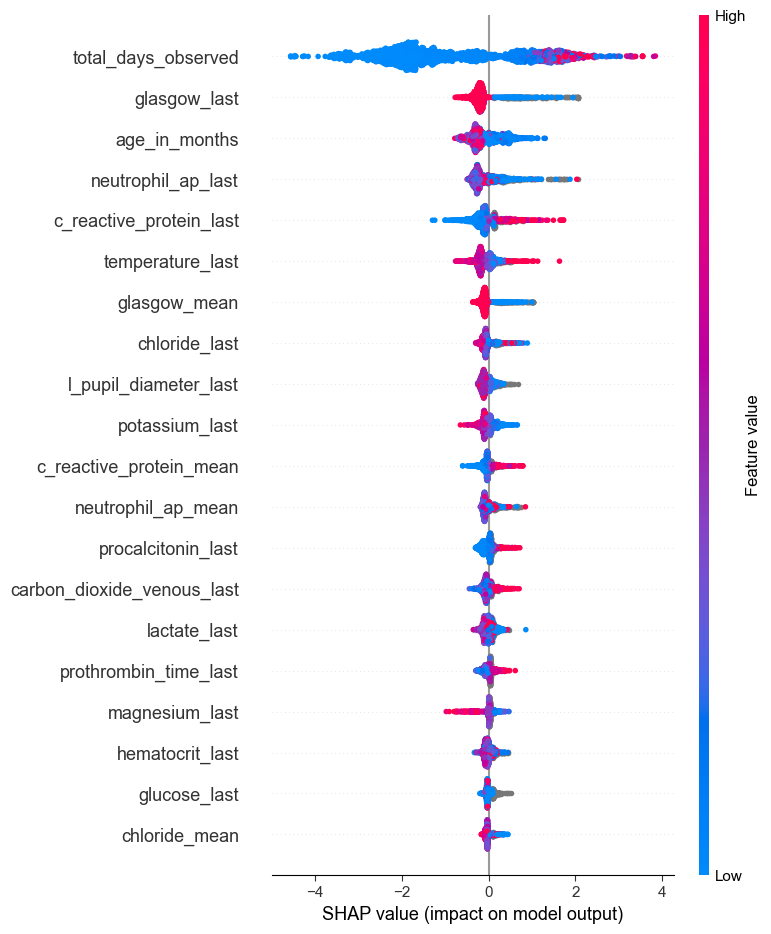

In [ ]:
import shap
import numpy as np

# Treinar modelo base completo
xgb_base = best_estimator48h
#xgb_base.fit(X_train48h, y_train48h)

explainer = shap.TreeExplainer(xgb_base)
shap_values = explainer.shap_values(X_train48h)

# Média absoluta de importância
shap_importance = np.abs(shap_values).mean(axis=0)

shap_df = (
    pd.DataFrame({
        "feature": X_train48h.columns,
        "importance": shap_importance
    })
    .sort_values("importance", ascending=False)
)
n=20
top = shap_df.head(n)["feature"].tolist()

# SHAP Top 20
shap_values = explainer.shap_values(X_train48h)  # Amostra para velocidade
shap.summary_plot(shap_values, X_train48h, max_display=n)



# SALVA MODELO, FEATURES e THRESHOLD AJUSTADO

In [ ]:
import joblib

joblib.dump(best_estimator48h, "modelo_sepse.pkl"), joblib.dump(df_final48h.columns.to_list(), "features_sepse.pkl"), joblib.dump(best_threshold, "threshold_sepse.pkl")

# joblib.dump(scaler, "scaler_sepse.pkl")


(['modelo_sepse.pkl'], ['features_sepse.pkl'], ['threshold_sepse.pkl'])

# #########  FIM #######.

In [ ]:
# l = [c for c in X_train48h.columns if c.endswith('_measured')]
# rc = []
# for i in l:
#     for i2 in top[1:]:
#         if i.startswith(i2):
#             rc.append(i)


# for x in rc:
#     top.append(x)

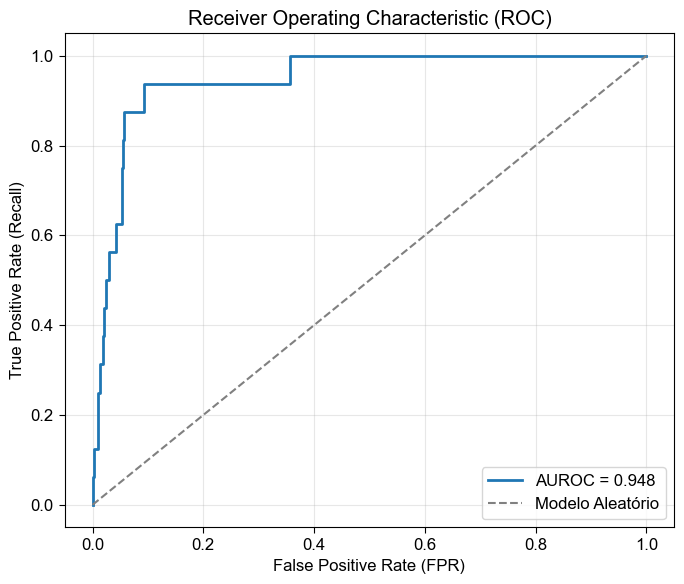

In [ ]:
from sklearn.metrics import roc_curve, roc_auc_score
import matplotlib.pyplot as plt
import numpy as np

# Probabilidades do modelo
y_prob24 = best_xgb24h.predict_proba(X_test24h)[:, 1]

# Calcular curva ROC
fpr, tpr, thresholds = roc_curve(y_test24h, y_prob24)

# Calcular AUC
roc_auc = roc_auc_score(y_test24h, y_prob24)

# Plot
plt.figure(figsize=(7,6))
plt.plot(fpr, tpr, linewidth=2, label=f'AUROC = {roc_auc:.3f}')
plt.plot([0,1], [0,1], linestyle='--', color='gray', label='Modelo Aleatório')

plt.xlabel('False Positive Rate (FPR)')
plt.ylabel('True Positive Rate (Recall)')
plt.title('Receiver Operating Characteristic (ROC)')
plt.legend()
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()


In [ ]:
best_estimator24h

,"objective objective: typing.Union[str, xgboost.sklearn._SklObjWProto, typing.Callable[[typing.Any, typing.Any], typing.Tuple[numpy.ndarray, numpy.ndarray]], NoneType]Specify the learning task and the corresponding learning objective or a customobjective function to be used.For custom objective, see :doc:`/tutorials/custom_metric_obj` and:ref:`custom-obj-metric` for more information, along with the end note forfunction signatures.",'binary:logistic'
,"base_score base_score: typing.Union[float, typing.List[float], NoneType]The initial prediction score of all instances, global bias.",None
,booster,None
,"callbacks callbacks: typing.Optional[typing.List[xgboost.callback.TrainingCallback]]List of callback functions that are applied at end of each iteration.It is possible to use predefined callbacks by using:ref:`Callback API `... note:: States in callback are not preserved during training, which means callback objects can not be reused for multiple training sessions without reinitialization or deepcopy... code-block:: python for params in parameters_grid: # be sure to (re)initialize the callbacks before each run callbacks = [xgb.callback.LearningRateScheduler(custom_rates)] reg = xgboost.XGBRegressor(**params, callbacks=callbacks) reg.fit(X, y)",None
,colsample_bylevel colsample_bylevel: typing.Optional[float]Subsample ratio of columns for each level.,None
,colsample_bynode colsample_bynode: typing.Optional[float]Subsample ratio of columns for each split.,None
,colsample_bytree colsample_bytree: typing.Optional[float]Subsample ratio of columns when constructing each tree.,0.6
,"device device: typing.Optional[str].. versionadded:: 2.0.0Device ordinal, available options are `cpu`, `cuda`, and `gpu`.",None
,"early_stopping_rounds early_stopping_rounds: typing.Optional[int].. versionadded:: 1.6.0- Activates early stopping. Validation metric needs to improve at least once in every **early_stopping_rounds** round(s) to continue training. Requires at least one item in **eval_set** in :py:meth:`fit`.- If early stopping occurs, the model will have two additional attributes: :py:attr:`best_score` and :py:attr:`best_iteration`. These are used by the :py:meth:`predict` and :py:meth:`apply` methods to determine the optimal number of trees during inference. If users want to access the full model (including trees built after early stopping), they can specify the `iteration_range` in these inference methods. In addition, other utilities like model plotting can also use the entire model.- If you prefer to discard the trees after `best_iteration`, consider using the callback function :py:class:`xgboost.callback.EarlyStopping`.- If there's more than one item in **eval_set**, the last entry will be used for early stopping. If there's more than one metric in **eval_metric**, the last metric will be used for early stopping.",None
,enable_categorical enable_categorical: boolSee the same parameter of :py:class:`DMatrix` for details.,False
,"eval_metric eval_metric: typing.Union[str, typing.List[typing.Union[str, typing.Callable]], typing.Callable, NoneType].. versionadded:: 1.6.0Metric used for monitoring the training result and early stopping. It can be astring or list of strings as names of predefined metric in XGBoost (See:doc:`/parameter`), one of the metrics in :py:mod:`sklearn.metrics`, or anyother user defined metric that looks like `sklearn.metrics`.If custom objective is also provided, then custom metric should implement thecorresponding reverse link function.Unlike the `scoring` parameter commonly used in scikit-learn, when a callableobject is provided, it's assumed to be a cost function and by default XGBoostwill minimize the result during early stopping.For advanced usage on Early stopping like directly choosing to maximize insteadof minimize, see :py:obj:`xgboost.callback.EarlyStopping`.See :doc:`/tutorials/custom_metric_obj` and :ref:`custom-obj-metric` for moreinformation... code-block:: python from sklearn.datasets import load_diabetes f

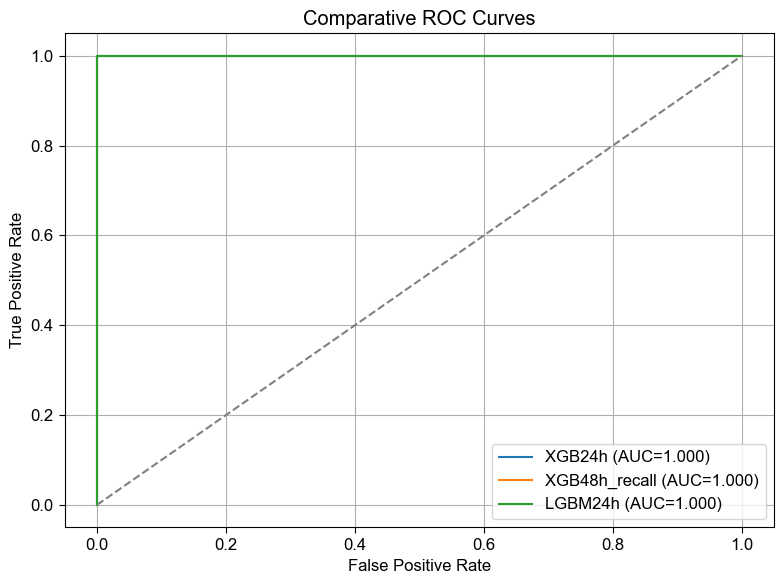

In [ ]:
from sklearn.metrics import roc_curve, roc_auc_score
import matplotlib.pyplot as plt

plt.figure(figsize=(8,6))

models = {
    "XGB24h": (best_xgb24h, X_test24h, y_test24h),
    "XGB48h_recall": (best_xgb_r, X_test48h, y_test48h),
    "LGBM24h": (best_lgbm24h, X_test24h, y_test24h)
}

for name, (model, X, y) in models.items():
    prob = model.predict_proba(X)[:,1]
    fpr, tpr, _ = roc_curve(y, prob)
    auc = roc_auc_score(y, prob)
    plt.plot(fpr, tpr, label=f"{name} (AUC={auc:.3f})")

plt.plot([0,1], [0,1], linestyle='--', color='gray')

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("Comparative ROC Curves")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()


# TERMINO

# GRAFICO MISSINGS

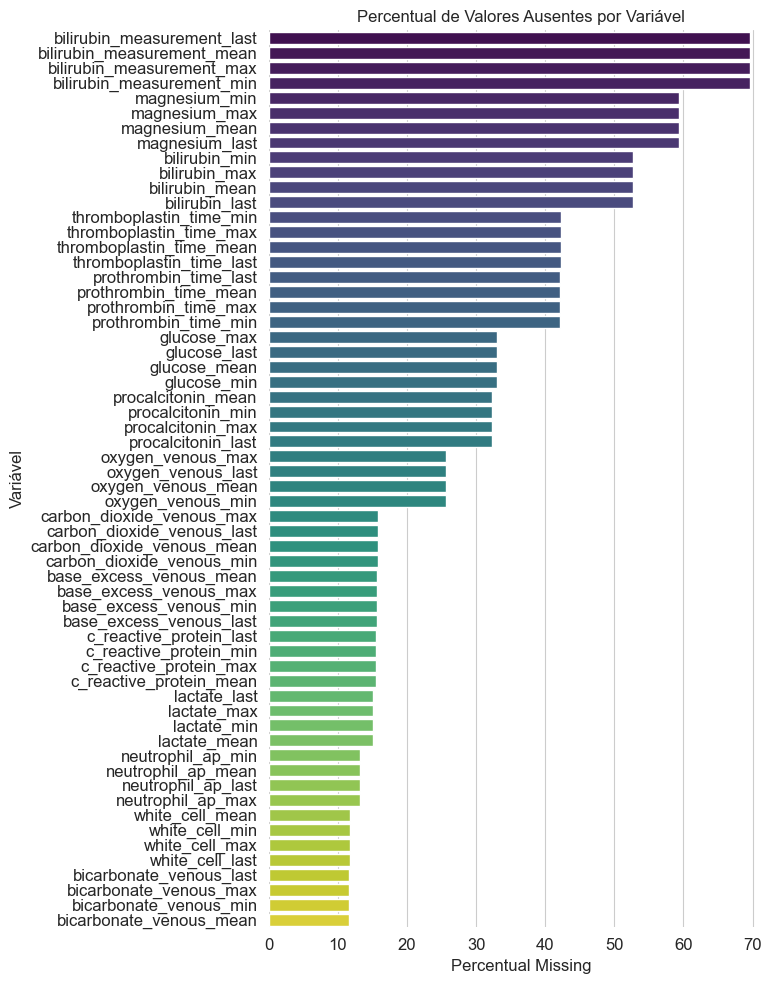

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

colunas_originais = [c for c in X_train24h.columns if not c.endswith('_measured')]

# Calcular percentual de missing
missing_percent = X_train24h[colunas_originais].isnull().mean() * 100

# Criar dataframe ordenado
missing_df = (
    missing_percent
    .sort_values(ascending=True)
    .reset_index()
)
missing_df.columns = ['Variável', 'Percentual Missing']

# Configuração visual profissional
plt.figure(figsize=(8, 10), dpi=100)
sns.set_style("whitegrid")

bar = sns.barplot(
    data=missing_df.sort_values(by='Percentual Missing', ascending=False)[:60],
    x='Percentual Missing',
    y='Variável',
    palette='viridis'
)

# Título
plt.title("Percentual de Valores Ausentes por Variável", fontsize=12)

# Remover bordas desnecessárias
sns.despine(left=True, bottom=True)

# Ajustar layout
plt.tight_layout()

plt.show()


In [ ]:
missing_df.sort_values(by='Percentual Missing', ascending=False)[:5]

NameError: name 'missing_df' is not defined